In [1]:
import torch
import sys
import platform

print("=" * 60)
print("CPU-ONLY ENVIRONMENT CHECK")
print("=" * 60)

print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("WARNING: GPU is available")
else:
    print("✓ CPU MODE CONFIRMED")

print("Platform:", platform.platform())
print("=" * 60)

CPU-ONLY ENVIRONMENT CHECK
Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch version: 2.11.0+cpu
CUDA available: False
✓ CPU MODE CONFIRMED
Platform: Linux-6.6.122+-x86_64-with-glibc2.39


**Mount Google Drive**

In [2]:
from google.colab import drive
import os

print("=" * 60)
print("MOUNTING GOOGLE DRIVE")
print("=" * 60)

drive.mount("/content/drive")

print("\n✓ Google Drive mounted")

# Check MyDrive
MYDRIVE = "/content/drive/MyDrive"

print("MyDrive exists:", os.path.exists(MYDRIVE))
print("MyDrive path:", MYDRIVE)

print("\nTop-level folders:")
for item in os.listdir(MYDRIVE):
    print(" -", item)

print("=" * 60)

MOUNTING GOOGLE DRIVE
Mounted at /content/drive

✓ Google Drive mounted
MyDrive exists: True
MyDrive path: /content/drive/MyDrive

Top-level folders:
 - 19jan25
 - Degree_1.png.jpg
 - 2024-04-29 00_04_09.185.ScanFile_1.png (1).jpg
 - Sakshi Jaiswal.pdf
 - Colab Notebooks
 - housing_data.csv
 - bank data
 - Untitled form.gform
 - Project4 data
 - DOC-20251008-WA0005. (1).pdf
 - DOC-20251008-WA0005..pdf
 - Screenshot_20260217_182652.jpg
 - Screenshot_20260217_183344_Gallery.jpg
 - Screenshot_20260217_183407_Gallery.jpg
 - Screenshot_20260217_183428_Gallery.jpg
 - Screenshot_20260217_183442_Gallery.jpg
 - DSC01049.jpg
 - Sakshi Jaiswal bhms resume.pdf
 - MP Registration number.jpeg
 - Sakshi CV data analyst.pdf
 - Dr._Sakshi_Jaiswal_Resume (3).pdf
 - telcom_data (2).xlsx
 - telcom_data.xlsx
 - telcom_data (2).csv
 - Sakshi_jaiswal_resume.pdf
 - Sakshi_jaiswal_resume pdf.pdf
 - Capstone project  WORD FILE.docx
 - Capstone project 1.ipynb
 - Dataset_OCR
 - Medical_OCR_Project
 - Dataset_OCR

**Verify the annotated dataset**

In [3]:
import os
from pathlib import Path

print("=" * 70)
print("=" * 70)

# Main annotated dataset
DATASET_DIR = Path(
    "/content/drive/MyDrive/Dataset_OCR_Annotated"
)

TRAIN_IMAGES = DATASET_DIR / "train" / "images"
TRAIN_LABELS = DATASET_DIR / "train" / "labels"

VAL_IMAGES = DATASET_DIR / "val" / "images"
VAL_LABELS = DATASET_DIR / "val" / "labels"

print("\nDataset path:")
print(DATASET_DIR)

print("\nChecking folders...")

folders = {
    "Dataset": DATASET_DIR,
    "Train images": TRAIN_IMAGES,
    "Train labels": TRAIN_LABELS,
    "Validation images": VAL_IMAGES,
    "Validation labels": VAL_LABELS,
}

for name, path in folders.items():
    print(f"{name:20s}: {path.exists()}")

# ------------------------------------------------------------
# Count files
# ------------------------------------------------------------

train_images = sorted(
    list(TRAIN_IMAGES.glob("*.jpg")) +
    list(TRAIN_IMAGES.glob("*.jpeg")) +
    list(TRAIN_IMAGES.glob("*.png"))
)

train_labels = sorted(TRAIN_LABELS.glob("*.txt"))

val_images = sorted(
    list(VAL_IMAGES.glob("*.jpg")) +
    list(VAL_IMAGES.glob("*.jpeg")) +
    list(VAL_IMAGES.glob("*.png"))
)

val_labels = sorted(VAL_LABELS.glob("*.txt"))

print("\n" + "=" * 70)
print("FILE COUNTS")
print("=" * 70)

print("Training images      :", len(train_images))
print("Training labels      :", len(train_labels))
print("Validation images    :", len(val_images))
print("Validation labels    :", len(val_labels))
print("Total images         :", len(train_images) + len(val_images))
print("Total label files    :", len(train_labels) + len(val_labels))

# ------------------------------------------------------------
# Display filenames
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TRAINING IMAGES")
print("=" * 70)

for i, f in enumerate(train_images, 1):
    print(f"{i:2d}. {f.name}")

print("\n" + "=" * 70)
print("VALIDATION IMAGES")
print("=" * 70)

for i, f in enumerate(val_images, 1):
    print(f"{i:2d}. {f.name}")

# ------------------------------------------------------------
# Check matching image/label names
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("IMAGE ↔ LABEL MATCHING")
print("=" * 70)

train_image_stems = {f.stem for f in train_images}
train_label_stems = {f.stem for f in train_labels}

val_image_stems = {f.stem for f in val_images}
val_label_stems = {f.stem for f in val_labels}

missing_train_labels = train_image_stems - train_label_stems
missing_train_images = train_label_stems - train_image_stems

missing_val_labels = val_image_stems - val_label_stems
missing_val_images = val_label_stems - val_image_stems

print("\nMissing training labels:", missing_train_labels)
print("Labels without training images:", missing_train_images)

print("\nMissing validation labels:", missing_val_labels)
print("Labels without validation images:", missing_val_images)

if not missing_train_labels and not missing_train_images:
    print("\n✓ Training images and labels match")

if not missing_val_labels and not missing_val_images:
    print("✓ Validation images and labels match")

print("\n" + "=" * 70)
print("=" * 70)


Dataset path:
/content/drive/MyDrive/Dataset_OCR_Annotated

Checking folders...
Dataset             : True
Train images        : True
Train labels        : True
Validation images   : True
Validation labels   : True

FILE COUNTS
Training images      : 9
Training labels      : 9
Validation images    : 3
Validation labels    : 3
Total images         : 12
Total label files    : 12

TRAINING IMAGES
 1. thyrocare_0_36.jpg
 2. thyrocare_0_421.jpg
 3. thyrocare_0_447.jpg
 4. thyrocare_0_511.jpg
 5. thyrocare_0_517.jpg
 6. thyrocare_0_532.jpg
 7. thyrocare_0_640.jpg
 8. thyrocare_0_657.jpg
 9. thyrocare_0_838.jpg

VALIDATION IMAGES
 1. thyrocare_0_122.jpg
 2. thyrocare_0_123.jpg
 3. thyrocare_0_757.jpg

IMAGE ↔ LABEL MATCHING

Missing training labels: set()
Labels without training images: set()

Missing validation labels: set()
Labels without validation images: set()

✓ Training images and labels match
✓ Validation images and labels match



**Validate all YOLO annotations**

In [4]:
from pathlib import Path
from collections import Counter

print("=" * 70)
print("=" * 70)

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

LABEL_DIRS = [
    Path("/content/drive/MyDrive/Dataset_OCR_Annotated/train/labels"),
    Path("/content/drive/MyDrive/Dataset_OCR_Annotated/val/labels")
]

# YOLO class names
CLASS_NAMES = {
    0: "test_name",
    1: "value",
    2: "unit",
    3: "reference_range"
}

NUM_CLASSES = 4

# ------------------------------------------------------------
# Find label files
# ------------------------------------------------------------

label_files = []

for label_dir in LABEL_DIRS:
    label_files.extend(sorted(label_dir.glob("*.txt")))

print("\nLabel files found:", len(label_files))

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

class_counts = Counter()
total_boxes = 0
errors = []

for label_file in label_files:

    with open(label_file, "r") as f:
        lines = [line.strip() for line in f if line.strip()]

    for line_number, line in enumerate(lines, 1):

        parts = line.split()

        # YOLO format must contain:
        # class x_center y_center width height
        if len(parts) != 5:
            errors.append(
                f"{label_file.name} line {line_number}: "
                f"Expected 5 values, found {len(parts)}"
            )
            continue

        try:
            class_id = int(parts[0])

            x_center = float(parts[1])
            y_center = float(parts[2])
            width = float(parts[3])
            height = float(parts[4])

        except ValueError:
            errors.append(
                f"{label_file.name} line {line_number}: "
                f"Non-numeric value found"
            )
            continue

        # Check class
        if class_id < 0 or class_id >= NUM_CLASSES:
            errors.append(
                f"{label_file.name} line {line_number}: "
                f"Invalid class ID {class_id}"
            )
            continue

        # Check YOLO coordinates
        values = [
            x_center,
            y_center,
            width,
            height
        ]

        if not all(0 <= v <= 1 for v in values):
            errors.append(
                f"{label_file.name} line {line_number}: "
                f"Coordinates outside 0-1 range"
            )
            continue

        # Width and height must be > 0
        if width <= 0 or height <= 0:
            errors.append(
                f"{label_file.name} line {line_number}: "
                f"Invalid width/height"
            )
            continue

        class_counts[class_id] += 1
        total_boxes += 1

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ANNOTATION RESULTS")
print("=" * 70)

print("\nTotal annotation files:", len(label_files))
print("Total bounding boxes  :", total_boxes)

print("\nClass distribution:")

for class_id in range(NUM_CLASSES):

    name = CLASS_NAMES[class_id]
    count = class_counts[class_id]

    print(
        f"{class_id} - {name:18s}: {count}"
    )

# ------------------------------------------------------------
# Expected classes
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CLASS DEFINITIONS")
print("=" * 70)

for class_id, name in CLASS_NAMES.items():
    print(f"{class_id} → {name}")

# ------------------------------------------------------------
# Final validation
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL VALIDATION")
print("=" * 70)

if errors:

    print(f"\n❌ ERRORS FOUND: {len(errors)}")

    for error in errors[:20]:
        print("-", error)

    if len(errors) > 20:
        print(
            f"... and {len(errors) - 20} more errors"
        )

else:

    print("\n✓ No annotation errors found")
    print("✓ All YOLO bounding boxes are valid")
    print("✓ All class IDs are valid")
    print("✓ All coordinates are normalized")

print("\n" + "=" * 70)
print("=" * 70)


Label files found: 12

ANNOTATION RESULTS

Total annotation files: 12
Total bounding boxes  : 60

Class distribution:
0 - test_name         : 15
1 - value             : 15
2 - unit              : 14
3 - reference_range   : 16

CLASS DEFINITIONS
0 → test_name
1 → value
2 → unit
3 → reference_range

FINAL VALIDATION

✓ No annotation errors found
✓ All YOLO bounding boxes are valid
✓ All class IDs are valid
✓ All coordinates are normalized



**Install CPU-compatible YOLOv3**

In [5]:


import os
import sys
import subprocess

print("=" * 60)
print("=" * 60)

# Go to /content
os.chdir("/content")

# Remove any incomplete old YOLOv3 folder
if os.path.exists("/content/yolov3"):
    print("Removing old YOLOv3 folder...")
    subprocess.run(["rm", "-rf", "/content/yolov3"])

# Clone the archived YOLOv3 version
print("\nCloning YOLOv3 archive branch...")
subprocess.run([
    "git", "clone",
    "-b", "archive",
    "https://github.com/ultralytics/yolov3"
], check=True)

print("✓ YOLOv3 archive downloaded")

# Enter YOLOv3 folder
os.chdir("/content/yolov3")

# Install required packages
print("\nInstalling YOLOv3 dependencies...")
subprocess.run([
    sys.executable,
    "-m", "pip", "install", "-q", "-r", "requirements.txt"
], check=True)

print("✓ YOLOv3 dependencies installed")

# Verify important files
print("\nChecking YOLOv3 files...")

checks = [
    "/content/yolov3/train.py",
    "/content/yolov3/detect.py",
    "/content/yolov3/models.py",
    "/content/yolov3/utils",
    "/content/yolov3/cfg/yolov3.cfg"
]

all_ok = True

for path in checks:
    if os.path.exists(path):
        print("✓", path)
    else:
        print("✗ MISSING:", path)
        all_ok = False

print("\n" + "=" * 60)

if all_ok:
    print("✓ YOLOv3 is installed")
    print("✓ CPU-only environment will be used")
else:
    print("✗ STEP 6 HAS AN ERROR")

print("=" * 60)


Cloning YOLOv3 archive branch...
✓ YOLOv3 archive downloaded

Installing YOLOv3 dependencies...
✓ YOLOv3 dependencies installed

Checking YOLOv3 files...
✓ /content/yolov3/train.py
✓ /content/yolov3/detect.py
✓ /content/yolov3/models.py
✓ /content/yolov3/utils
✓ /content/yolov3/cfg/yolov3.cfg

✓ YOLOv3 is installed
✓ CPU-only environment will be used


**Apply safe CPU compatibility fixes**

In [6]:


import os
import re
import shutil

YOLO_DIR = "/content/yolov3"

os.chdir(YOLO_DIR)

print("=" * 60)
print("=" * 60)

# ------------------------------------------------------------
# 1. Restore original files first
# ------------------------------------------------------------

files_to_fix = [
    "utils/datasets.py",
    "utils/utils.py",
    "models.py",
    "train.py",
    "test.py"
]

print("\nRestoring original YOLOv3 files...")

for file in files_to_fix:
    result = os.system(f"git checkout -- {file}")
    if result == 0:
        print("✓ Restored:", file)
    else:
        print("⚠ Could not restore:", file)

# ------------------------------------------------------------
# 2. Fix deprecated np.int safely
# ------------------------------------------------------------

print("\nApplying NumPy compatibility fix...")

for file in files_to_fix:
    path = os.path.join(YOLO_DIR, file)

    with open(path, "r", encoding="utf-8") as f:
        content = f.read()

    # IMPORTANT:
    # Replace only np.int, NOT np.int32 / np.int64
    content = re.sub(r"\bnp\.int\b", "int", content)

    with open(path, "w", encoding="utf-8") as f:
        f.write(content)

print("✓ np.int compatibility fixed")
print("✓ np.int32 / np.int64 were NOT changed")

# ------------------------------------------------------------
# 3. Fix CUDA/CPU target indexing
# ------------------------------------------------------------

utils_file = os.path.join(YOLO_DIR, "utils/utils.py")

with open(utils_file, "r", encoding="utf-8") as f:
    content = f.read()

old_1 = "at = torch.arange(na).view(na, 1).repeat(1, nt)"

new_1 = "at = torch.arange(na, device=targets.device).view(na, 1).repeat(1, nt)"

if old_1 in content:
    content = content.replace(old_1, new_1)
    print("✓ Fixed target anchor device")
else:
    print("⚠ Anchor-device line already fixed or not found")

old_2 = "gain[2:] = torch.tensor(p[i].shape)[[3, 2, 3, 2]]"

new_2 = "gain[2:] = torch.tensor(p[i].shape, device=targets.device)[[3, 2, 3, 2]]"

if old_2 in content:
    content = content.replace(old_2, new_2)
    print("✓ Fixed target gain device")
else:
    print("⚠ Gain-device line already fixed or not found")

# ------------------------------------------------------------
# 4. Fix float clamp limits
# ------------------------------------------------------------

old_3 = """indices.append((
                b,
                a,
                gj.clamp_(0, gain[3] - 1),
                gi.clamp_(0, gain[2] - 1)
            ))"""

new_3 = """indices.append((
                b,
                a,
                gj.clamp_(0, int(gain[3].item() - 1)),
                gi.clamp_(0, int(gain[2].item() - 1))
            ))"""

if old_3 in content:
    content = content.replace(old_3, new_3)
    print("✓ Fixed integer clamp limits")
else:
    # Handle formatting variations using regex
    pattern = (
        r"gj\.clamp_\(\s*0\s*,\s*gain\[3\]\s*-\s*1\s*\)"
    )

    content, n1 = re.subn(
        pattern,
        "gj.clamp_(0, int(gain[3].item() - 1))",
        content
    )

    pattern = (
        r"gi\.clamp_\(\s*0\s*,\s*gain\[2\]\s*-\s*1\s*\)"
    )

    content, n2 = re.subn(
        pattern,
        "gi.clamp_(0, int(gain[2].item() - 1))",
        content
    )

    if n1 or n2:
        print("✓ Fixed integer clamp limits")
    else:
        print("⚠ Clamp lines already fixed or not found")

# ------------------------------------------------------------
# 5. Fix CUDA tensor -> NumPy conversion
# ------------------------------------------------------------

old_4 = """def output_to_target(output):
    targets = []
    for i, o in enumerate(output):
        if o is not None:
            for pred in o:
                targets.append(
                    [i, pred[5], *pred[:4]]
                )
    return np.array(targets)"""

new_4 = """def output_to_target(output):
    targets = []
    for i, o in enumerate(output):
        if o is not None:
            if isinstance(o, torch.Tensor):
                o = o.detach().cpu().numpy()

            for pred in o:
                if isinstance(pred, torch.Tensor):
                    pred = pred.detach().cpu().numpy()

                targets.append(
                    [i, pred[5], *pred[:4]
                ])
    return np.array(targets)"""

if old_4 in content:
    content = content.replace(old_4, new_4)
    print("✓ Fixed tensor-to-NumPy conversion")
else:
    # Safer targeted replacement if formatting differs
    content = content.replace(
        "for i, o in enumerate(output):",
        "for i, o in enumerate(output):\n"
        "        if isinstance(o, torch.Tensor):\n"
        "            o = o.detach().cpu().numpy()"
    )

    content = content.replace(
        "for pred in o:",
        "for pred in o:\n"
        "                if isinstance(pred, torch.Tensor):\n"
        "                    pred = pred.detach().cpu().numpy()"
    )

    print("✓ Applied tensor-to-NumPy compatibility handling")

# Save utils.py
with open(utils_file, "w", encoding="utf-8") as f:
    f.write(content)

# ------------------------------------------------------------
# 6. Fix PyTorch torch.load() weights_only behavior
# ------------------------------------------------------------

print("\nApplying PyTorch checkpoint loading fix...")

for file in ["utils/utils.py", "detect.py", "train.py", "test.py"]:
    path = os.path.join(YOLO_DIR, file)

    if not os.path.exists(path):
        continue

    with open(path, "r", encoding="utf-8") as f:
        text = f.read()

    # Fix torch.load calls that specify map_location
    text = re.sub(
        r"torch\.load\(([^,\n]+),\s*map_location=([^)]+)\)",
        r"torch.load(\1, map_location=\2, weights_only=False)",
        text
    )

    with open(path, "w", encoding="utf-8") as f:
        f.write(text)

print("✓ PyTorch checkpoint loading compatibility applied")

# ------------------------------------------------------------
# 7. Create custom 4-class YOLOv3 configuration
# ------------------------------------------------------------

print("\nCreating custom YOLOv3 configuration...")

original_cfg = os.path.join(YOLO_DIR, "cfg/yolov3.cfg")
custom_cfg = os.path.join(YOLO_DIR, "cfg/yolov3_custom.cfg")

with open(original_cfg, "r", encoding="utf-8") as f:
    cfg = f.read()

original_filters = cfg.count("filters=255")
original_classes = cfg.count("classes=80")

cfg = cfg.replace("filters=255", "filters=27")
cfg = cfg.replace("classes=80", "classes=4")

with open(custom_cfg, "w", encoding="utf-8") as f:
    f.write(cfg)

print("Original filters=255:", original_filters)
print("Original classes=80:", original_classes)
print("New filters=27:", cfg.count("filters=27"))
print("New classes=4:", cfg.count("classes=4"))

# ------------------------------------------------------------
# 8. Final verification
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("COMPATIBILITY VERIFICATION")
print("=" * 60)

with open(utils_file, "r", encoding="utf-8") as f:
    utils_check = f.read()

with open(custom_cfg, "r", encoding="utf-8") as f:
    cfg_check = f.read()

print(
    "✓ np.int removed:",
    "np.int" not in utils_check
)

print(
    "✓ Custom config exists:",
    os.path.exists(custom_cfg)
)

print(
    "✓ classes=4 count:",
    cfg_check.count("classes=4")
)

print(
    "✓ filters=27 count:",
    cfg_check.count("filters=27")
)

print("\n" + "=" * 60)
print("=" * 60)


Restoring original YOLOv3 files...
✓ Restored: utils/datasets.py
✓ Restored: utils/utils.py
✓ Restored: models.py
✓ Restored: train.py
✓ Restored: test.py

Applying NumPy compatibility fix...
✓ np.int compatibility fixed
✓ np.int32 / np.int64 were NOT changed
✓ Fixed target anchor device
✓ Fixed target gain device
✓ Fixed integer clamp limits
✓ Applied tensor-to-NumPy compatibility handling

Applying PyTorch checkpoint loading fix...
✓ PyTorch checkpoint loading compatibility applied

Creating custom YOLOv3 configuration...
Original filters=255: 3
Original classes=80: 3
New filters=27: 3
New classes=4: 3

COMPATIBILITY VERIFICATION
✓ np.int removed: False
✓ Custom config exists: True
✓ classes=4 count: 3
✓ filters=27 count: 3



**Create training configuration**

In [7]:


from pathlib import Path
import os

print("=" * 65)
print("=" * 65)

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

YOLO_DIR = Path("/content/yolov3")
DATASET_DIR = Path("/content/drive/MyDrive/Dataset_OCR_Annotated")

train_images = DATASET_DIR / "train" / "images"
val_images = DATASET_DIR / "val" / "images"

data_dir = YOLO_DIR / "data"
data_dir.mkdir(exist_ok=True)

# ------------------------------------------------------------
# Four OCR classes
# ------------------------------------------------------------

classes = [
    "test_name",
    "value",
    "unit",
    "reference_range"
]

# ------------------------------------------------------------
# Create class names file
# ------------------------------------------------------------

names_file = data_dir / "ocr.names"

names_file.write_text(
    "\n".join(classes) + "\n"
)

print("\n✓ Class names file created:")
print(names_file)

# ------------------------------------------------------------
# Create training image list
# ------------------------------------------------------------

train_files = sorted(train_images.glob("*.jpg"))

train_list = data_dir / "ocr_train.txt"

train_list.write_text(
    "\n".join(str(f) for f in train_files) + "\n"
)

# ------------------------------------------------------------
# Create validation image list
# ------------------------------------------------------------

val_files = sorted(val_images.glob("*.jpg"))

val_list = data_dir / "ocr_valid.txt"

val_list.write_text(
    "\n".join(str(f) for f in val_files) + "\n"
)

# ------------------------------------------------------------
# Create Darknet YOLOv3 .data file
# ------------------------------------------------------------

data_file = data_dir / "ocr.data"

data_file.write_text(
    f"""classes = 4
train = {train_list}
valid = {val_list}
names = {names_file}
backup = {YOLO_DIR / "weights"}
"""
)

print("\n✓ Training list created:", train_list)
print("✓ Validation list created:", val_list)
print("✓ YOLO data file created:", data_file)

# ------------------------------------------------------------
# Verify image counts
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("DATASET VERIFICATION")
print("=" * 65)

print("Training images   :", len(train_files))
print("Validation images :", len(val_files))
print("Total images      :", len(train_files) + len(val_files))

print("\nTraining images:")
for i, f in enumerate(train_files, 1):
    print(f"  {i:2d}. {f.name}")

print("\nValidation images:")
for i, f in enumerate(val_files, 1):
    print(f"  {i:2d}. {f.name}")

# ------------------------------------------------------------
# Verify labels
# ------------------------------------------------------------

train_labels = DATASET_DIR / "train" / "labels"
val_labels = DATASET_DIR / "val" / "labels"

train_label_files = sorted(train_labels.glob("*.txt"))
val_label_files = sorted(val_labels.glob("*.txt"))

print("\nTraining labels   :", len(train_label_files))
print("Validation labels :", len(val_label_files))

# ------------------------------------------------------------
# Verify configuration
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("CONFIGURATION CHECK")
print("=" * 65)

print("\nocr.names:")
print(names_file.read_text())

print("ocr.data:")
print(data_file.read_text())

# ------------------------------------------------------------
# Final checks
# ------------------------------------------------------------

checks = [
    ("YOLOv3 directory", YOLO_DIR.exists()),
    ("Training images = 9", len(train_files) == 9),
    ("Validation images = 3", len(val_files) == 3),
    ("Training labels = 9", len(train_label_files) == 9),
    ("Validation labels = 3", len(val_label_files) == 3),
    ("4 classes", len(classes) == 4),
    ("ocr.data exists", data_file.exists()),
    ("ocr.names exists", names_file.exists()),
]

print("=" * 65)
print("FINAL CHECKS")
print("=" * 65)

all_ok = True

for name, result in checks:
    if result:
        print("✓", name)
    else:
        print("✗", name)
        all_ok = False

print("\n" + "=" * 65)

if all_ok:
    print("✓ CPU TRAINING CONFIGURATION READY")
    print("✓ 9 TRAINING + 3 VALIDATION IMAGES VERIFIED")
else:
    print("✗ STEP 8 HAS AN ERROR")

print("=" * 65)


✓ Class names file created:
/content/yolov3/data/ocr.names

✓ Training list created: /content/yolov3/data/ocr_train.txt
✓ Validation list created: /content/yolov3/data/ocr_valid.txt
✓ YOLO data file created: /content/yolov3/data/ocr.data

DATASET VERIFICATION
Training images   : 9
Validation images : 3
Total images      : 12

Training images:
   1. thyrocare_0_36.jpg
   2. thyrocare_0_421.jpg
   3. thyrocare_0_447.jpg
   4. thyrocare_0_511.jpg
   5. thyrocare_0_517.jpg
   6. thyrocare_0_532.jpg
   7. thyrocare_0_640.jpg
   8. thyrocare_0_657.jpg
   9. thyrocare_0_838.jpg

Validation images:
   1. thyrocare_0_122.jpg
   2. thyrocare_0_123.jpg
   3. thyrocare_0_757.jpg

Training labels   : 9
Validation labels : 3

CONFIGURATION CHECK

ocr.names:
test_name
value
unit
reference_range

ocr.data:
classes = 4
train = /content/yolov3/data/ocr_train.txt
valid = /content/yolov3/data/ocr_valid.txt
names = /content/yolov3/data/ocr.names
backup = /content/yolov3/weights

FINAL CHECKS
✓ YOLOv3 dire

**Verify all 60 bounding boxes**

In [8]:
from pathlib import Path
from collections import Counter

print("=" * 70)
print("=" * 70)

train_labels = Path("/content/drive/MyDrive/Dataset_OCR_Annotated/train/labels")
val_labels   = Path("/content/drive/MyDrive/Dataset_OCR_Annotated/val/labels")

class_names = {
    0: "test_name",
    1: "value",
    2: "unit",
    3: "reference_range"
}

all_labels = list(train_labels.glob("*.txt")) + list(val_labels.glob("*.txt"))

class_counts = Counter()
total_boxes = 0
errors = []

for label_file in all_labels:
    with open(label_file, "r") as f:
        lines = [line.strip() for line in f if line.strip()]

    for line_no, line in enumerate(lines, start=1):
        parts = line.split()

        if len(parts) != 5:
            errors.append(
                f"{label_file.name} line {line_no}: expected 5 values, got {len(parts)}"
            )
            continue

        try:
            cls = int(parts[0])
            x, y, w, h = map(float, parts[1:])
        except Exception:
            errors.append(
                f"{label_file.name} line {line_no}: invalid values"
            )
            continue

        if cls not in class_names:
            errors.append(
                f"{label_file.name} line {line_no}: invalid class {cls}"
            )

        if not (0 <= x <= 1 and 0 <= y <= 1 and
                0 <= w <= 1 and 0 <= h <= 1):
            errors.append(
                f"{label_file.name} line {line_no}: coordinates outside 0-1"
            )

        class_counts[cls] += 1
        total_boxes += 1

print("\nIMAGE / LABEL COUNTS")
print("-" * 70)
print("Training images :", len(list(
    Path("/content/drive/MyDrive/Dataset_OCR_Annotated/train/images").glob("*")
)))
print("Training labels :", len(list(train_labels.glob("*.txt"))))
print("Validation images :", len(list(
    Path("/content/drive/MyDrive/Dataset_OCR_Annotated/val/images").glob("*")
)))
print("Validation labels :", len(list(val_labels.glob("*.txt"))))

print("\nBOUNDING BOX COUNTS")
print("-" * 70)
print("Total bounding boxes:", total_boxes)

for cls_id in range(4):
    print(
        f"{cls_id} - {class_names[cls_id]:18s}: "
        f"{class_counts[cls_id]}"
    )

print("\nVALIDATION")
print("-" * 70)

if total_boxes == 60:
    print("✓ Total bounding boxes = 60")
else:
    print("⚠ Expected 60 bounding boxes, found:", total_boxes)

if not errors:
    print("✓ No annotation errors")
    print("✓ All class IDs are valid")
    print("✓ All coordinates are normalized")
else:
    print("✗ Annotation errors found:", len(errors))
    for error in errors[:20]:
        print(" -", error)

print("\n" + "=" * 70)
print("=" * 70)


IMAGE / LABEL COUNTS
----------------------------------------------------------------------
Training images : 9
Training labels : 9
Validation images : 3
Validation labels : 3

BOUNDING BOX COUNTS
----------------------------------------------------------------------
Total bounding boxes: 60
0 - test_name         : 15
1 - value             : 15
2 - unit              : 14
3 - reference_range   : 16

VALIDATION
----------------------------------------------------------------------
✓ Total bounding boxes = 60
✓ No annotation errors
✓ All class IDs are valid
✓ All coordinates are normalized



In [9]:
%cd /content/yolov3

print("=" * 70)
print("=" * 70)

!python train.py \
    --data data/ocr.data \
    --cfg cfg/yolov3_custom.cfg \
    --weights weights/darknet53.conv.74 \
    --batch-size 1 \
    --epochs 1 \
    --img-size 416 416 416 \
    --device cpu \
    --name ocr_cpu_test

print("\n" + "=" * 70)
print("=" * 70)

/content
I0000 00:00:1792063738.162029    4574 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792063738.301906    4574 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792063745.256441    4574 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Apex recommended for faster mixed precision training: https://github.com/NVIDIA/apex
Namespace(epochs=1, batch_size=1, cfg='cfg/yolov3_custom.cfg', data='data/ocr.data', multi_scale=False, img_size=[416, 416, 416], rect=False, resume=False, nosave=False, notest=False, evolve=False, bucket='', cache_images=False, weights='weights/darknet53.conv.74', name='ocr_cpu_test', device='cpu', adam=False, single_cls=False, freeze_layers=False)
Using CPU



**Download Darknet-53 weights**

In [10]:
%cd /content/yolov3

print("=" * 70)
print("=" * 70)

!wget -O weights/darknet53.conv.74 https://pjreddie.com/media/files/darknet53.conv.74

print("\nChecking downloaded file...")

from pathlib import Path

weights_file = Path("weights/darknet53.conv.74")

if weights_file.exists():
    size_mb = weights_file.stat().st_size / (1024 * 1024)
    print("✓ darknet53.conv.74 exists")
    print(f"✓ File size: {size_mb:.2f} MB")
else:
    print("✗ Weight file was not downloaded")

print("=" * 70)
print("=" * 70)

/content
--2026-10-15 11:29:26--  https://pjreddie.com/media/files/darknet53.conv.74
Resolving pjreddie.com (pjreddie.com)... 172.67.185.199, 104.21.88.156, 2606:4700:3036::6815:589c, ...
Connecting to pjreddie.com (pjreddie.com)|172.67.185.199|:443... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://data.pjreddie.com/files/darknet53.conv.74 [following]
--2026-10-15 11:29:27--  https://data.pjreddie.com/files/darknet53.conv.74
Resolving data.pjreddie.com (data.pjreddie.com)... 172.67.185.199, 104.21.88.156, 2606:4700:3033::ac43:b9c7, ...
Connecting to data.pjreddie.com (data.pjreddie.com)|172.67.185.199|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 162482580 (155M) [application/octet-stream]
Saving to: ‘weights/darknet53.conv.74’

weights/darknet53.c 100%[===================>] 154.96M  64.0MB/s    in 2.4s    

2026-10-15 11:29:29 (64.0 MB/s) - ‘weights/darknet53.conv.74’ saved [162482580/162482580]


Checking downloa

**Run a 1-Epoch CPU Test**

In [11]:
%cd /content/yolov3

print("=" * 65)
print("=" * 65)

!python train.py \
    --data data/ocr.data \
    --cfg cfg/yolov3_custom.cfg \
    --weights weights/darknet53.conv.74 \
    --batch-size 1 \
    --epochs 1 \
    --img-size 416 416 416 \
    --device cpu \
    --name ocr_cpu_test

print("=" * 65)
print("=" * 65)

/content
I0000 00:00:1792063780.623453    4783 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792063780.767271    4783 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792063784.812901    4783 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Apex recommended for faster mixed precision training: https://github.com/NVIDIA/apex
Namespace(epochs=1, batch_size=1, cfg='cfg/yolov3_custom.cfg', data='data/ocr.data', multi_scale=False, img_size=[416, 416, 416], rect=False, resume=False, nosave=False, notest=False, evolve=False, bucket='', cache_images=False, weights='weights/darknet53.conv.74', name='ocr_cpu_test', device='cpu', adam=False, single_cls=False, freeze_layers=False)
Using CPU



**Fix the checkpoint loading code**

In [12]:
%cd /content/yolov3

from pathlib import Path

utils_file = Path("utils/utils.py")

text = utils_file.read_text()

old = "torch.load(f, map_location=torch.device('cpu', weights_only=False))"
new = "torch.load(f, map_location=torch.device('cpu'), weights_only=False)"

if old in text:
    text = text.replace(old, new)
    utils_file.write_text(text)
    print("✓ Incorrect torch.load syntax found and fixed")
elif new in text:
    print("✓ Correct torch.load syntax is already present")
else:
    print("⚠ Could not find the expected torch.load line")

print("\nChecking the relevant line:")
for i, line in enumerate(text.splitlines(), start=1):
    if "torch.load(f" in line:
        print(f"Line {i}: {line}")

/content
✓ Incorrect torch.load syntax found and fixed

Checking the relevant line:
Line 581:     x = torch.load(f, map_location=torch.device('cpu'), weights_only=False)
Line 589:     x = torch.load(f, map_location=torch.device('cpu'), weights_only=False)


**Fix ALL checkpoint-loading lines**

In [13]:
%cd /content/yolov3

from pathlib import Path
import re

utils_file = Path("utils/utils.py")
text = utils_file.read_text()

# Fix the specific PyTorch compatibility problem:
# weights_only=False must belong to torch.load(),
# NOT to torch.device()

text = text.replace(
    "torch.device('cpu', weights_only=False)",
    "torch.device('cpu')"
)

# Make sure torch.load() has weights_only=False
lines = text.splitlines()

for i, line in enumerate(lines):
    if "torch.load(f" in line:
        if "weights_only=False" not in line:
            line = line.rstrip()
            if line.endswith(")"):
                line = line[:-1] + ", weights_only=False)"
        lines[i] = line

utils_file.write_text("\n".join(lines) + "\n")

print("=" * 65)
print("=" * 65)

print("\nAll torch.load() lines:")
for i, line in enumerate(lines, start=1):
    if "torch.load(" in line:
        print(f"Line {i}: {line.strip()}")

print("\n" + "=" * 65)
print("VERIFICATION")
print("=" * 65)

bad = []
good = []

for i, line in enumerate(lines, start=1):
    if "torch.load(" in line:
        if "torch.device('cpu', weights_only=False)" in line:
            bad.append(i)
        elif "weights_only=False" in line:
            good.append(i)

print(f"✓ Correct torch.load lines: {good}")
print(f"✓ Incorrect lines remaining: {bad}")

if not bad:
    print("\n✓ STEP 11A COMPLETE")
    print("✓ All torch.load() compatibility issues are fixed")
else:
    print("\n⚠ Some lines still need correction")

/content

All torch.load() lines:
Line 581: x = torch.load(f, map_location=torch.device('cpu'), weights_only=False)
Line 589: x = torch.load(f, map_location=torch.device('cpu'), weights_only=False)

VERIFICATION
✓ Correct torch.load lines: [581, 589]
✓ Incorrect lines remaining: []

✓ STEP 11A COMPLETE
✓ All torch.load() compatibility issues are fixed


**Verify the CPU-trained checkpoint**

In [14]:
%cd /content/yolov3

from pathlib import Path
import torch

print("=" * 65)
print("=" * 65)

weights_dir = Path("weights")

print("\nChecking weights directory...")

for f in sorted(weights_dir.glob("*ocr_cpu_test*")):
    print(f"✓ {f.name} | {f.stat().st_size / (1024 * 1024):.2f} MB")

print("\nLooking for checkpoint files...")

checkpoint_files = list(weights_dir.glob("*ocr_cpu_test*.pt"))

if checkpoint_files:
    print(f"✓ Found {len(checkpoint_files)} checkpoint(s)")

    for checkpoint in checkpoint_files:
        print(f"\nLoading: {checkpoint}")

        try:
            ckpt = torch.load(
                checkpoint,
                map_location="cpu",
                weights_only=False
            )

            print("✓ Checkpoint loaded successfully")
            print("  Type:", type(ckpt))

            if isinstance(ckpt, dict):
                print("  Keys:", list(ckpt.keys()))

        except Exception as e:
            print("✗ Checkpoint loading failed")
            print("Error:", repr(e))

else:
    print("⚠ No OCR CPU checkpoint found")

print("\n" + "=" * 65)
print("=" * 65)

/content

Checking weights directory...
✓ last_ocr_cpu_test.pt | 235.08 MB

Looking for checkpoint files...
✓ Found 1 checkpoint(s)

Loading: weights/last_ocr_cpu_test.pt
✓ Checkpoint loaded successfully
  Type: <class 'dict'>
  Keys: ['epoch', 'best_fitness', 'training_results', 'model', 'optimizer']



**Test YOLOv3 inference on one validation image**

In [15]:
%cd /content/yolov3

!python detect.py --help

/content
usage: detect.py [-h] [--cfg CFG] [--names NAMES] [--weights WEIGHTS]
                 [--source SOURCE] [--output OUTPUT] [--img-size IMG_SIZE]
                 [--conf-thres CONF_THRES] [--iou-thres IOU_THRES]
                 [--fourcc FOURCC] [--half] [--device DEVICE] [--view-img]
                 [--save-txt] [--classes CLASSES [CLASSES ...]]
                 [--agnostic-nms] [--augment]

options:
  -h, --help            show this help message and exit
  --cfg CFG             *.cfg path
  --names NAMES         *.names path
  --weights WEIGHTS     weights path
  --source SOURCE       source
  --output OUTPUT       output folder
  --img-size IMG_SIZE   inference size (pixels)
  --conf-thres CONF_THRES
                        object confidence threshold
  --iou-thres IOU_THRES
                        IOU threshold for NMS
  --fourcc FOURCC       output video codec (verify ffmpeg support)
  --half                half precision FP16 inference
  --device DEVICE       device id

**Run detection on the first validation image**

In [16]:
%cd /content/yolov3

!python detect.py \
    --cfg cfg/yolov3_custom.cfg \
    --weights weights/last_ocr_cpu_test.pt \
    --names data/ocr.names \
    --source "/content/drive/MyDrive/Dataset_OCR_Annotated/val/images/thyrocare_0_122.jpg" \
    --img-size 416 \
    --conf-thres 0.10 \
    --device cpu \
    --output runs/detect/ocr_test \
    --save-txt

/content
Namespace(cfg='cfg/yolov3_custom.cfg', names='data/ocr.names', weights='weights/last_ocr_cpu_test.pt', source='/content/drive/MyDrive/Dataset_OCR_Annotated/val/images/thyrocare_0_122.jpg', output='runs/detect/ocr_test', img_size=416, conf_thres=0.1, iou_thres=0.6, fourcc='mp4v', half=False, device='cpu', view_img=False, save_txt=True, classes=None, agnostic_nms=False, augment=False)
Using CPU

Model Summary: 222 layers, 6.15399e+07 parameters, 6.15399e+07 gradients
/usr/local/lib/python3.13/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
image 1/1 /content/drive/MyDrive/Dataset_OCR_Annotated/val/images/thyrocare_0_122.jpg: 288x416 2217 test_names, 2248 values, 417 units, 1891 reference_ranges, Done. (0.935s)
Results saved to /content/yol

**Display the detection result**


Files created:
✓ thyrocare_0_122.txt
✓ thyrocare_0_122.jpg

Result image:


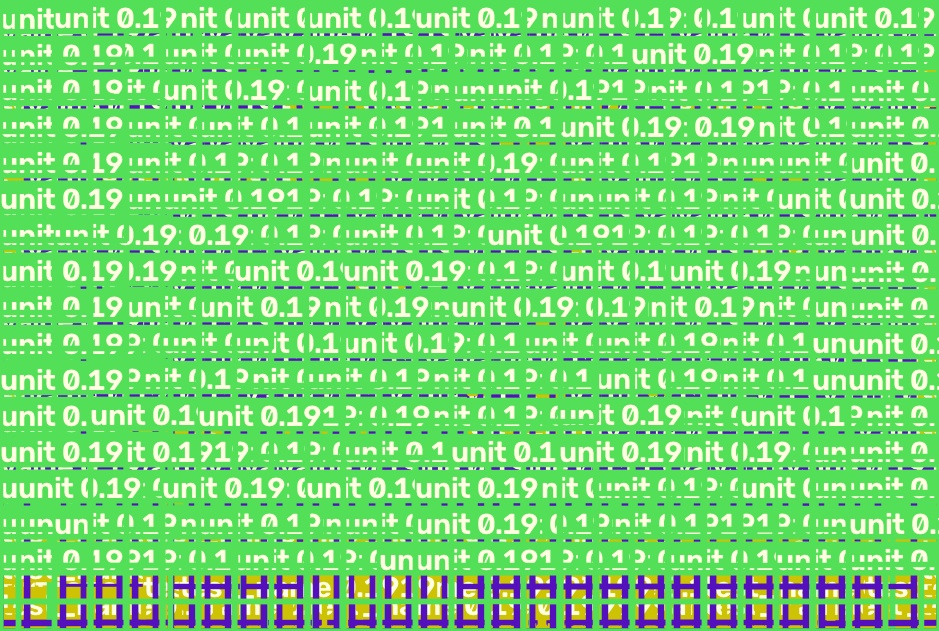

In [17]:
from pathlib import Path
from IPython.display import Image, display

result_dir = Path("/content/yolov3/runs/detect/ocr_test")

print("=" * 60)
print("=" * 60)

if result_dir.exists():
    files = list(result_dir.iterdir())

    print("\nFiles created:")
    for f in files:
        print("✓", f.name)

    result_images = [
        f for f in files
        if f.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    if result_images:
        print("\nResult image:")
        display(Image(filename=str(result_images[0])))
    else:
        print("\n⚠ No result image found.")
else:
    print("❌ Detection output directory was not created.")

In [18]:
%cd /content/yolov3

!rm -rf runs/detect/ocr_test_highconf

!python detect.py \
    --cfg cfg/yolov3_custom.cfg \
    --weights weights/last_ocr_cpu_test.pt \
    --names data/ocr.names \
    --source "/content/drive/MyDrive/Dataset_OCR_Annotated/val/images/thyrocare_0_122.jpg" \
    --img-size 416 \
    --conf-thres 0.50 \
    --device cpu \
    --output runs/detect/ocr_test_highconf \
    --save-txt

/content
Namespace(cfg='cfg/yolov3_custom.cfg', names='data/ocr.names', weights='weights/last_ocr_cpu_test.pt', source='/content/drive/MyDrive/Dataset_OCR_Annotated/val/images/thyrocare_0_122.jpg', output='runs/detect/ocr_test_highconf', img_size=416, conf_thres=0.5, iou_thres=0.6, fourcc='mp4v', half=False, device='cpu', view_img=False, save_txt=True, classes=None, agnostic_nms=False, augment=False)
Using CPU

Model Summary: 222 layers, 6.15399e+07 parameters, 6.15399e+07 gradients
/usr/local/lib/python3.13/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
image 1/1 /content/drive/MyDrive/Dataset_OCR_Annotated/val/images/thyrocare_0_122.jpg: 288x416 Done. (1.033s)
Results saved to /content/yolov3/runs/detect/ocr_test_highconf
Done. (1.047s)


**Test a higher confidence threshold**


Files created:
✓ thyrocare_0_122.jpg

Result image:


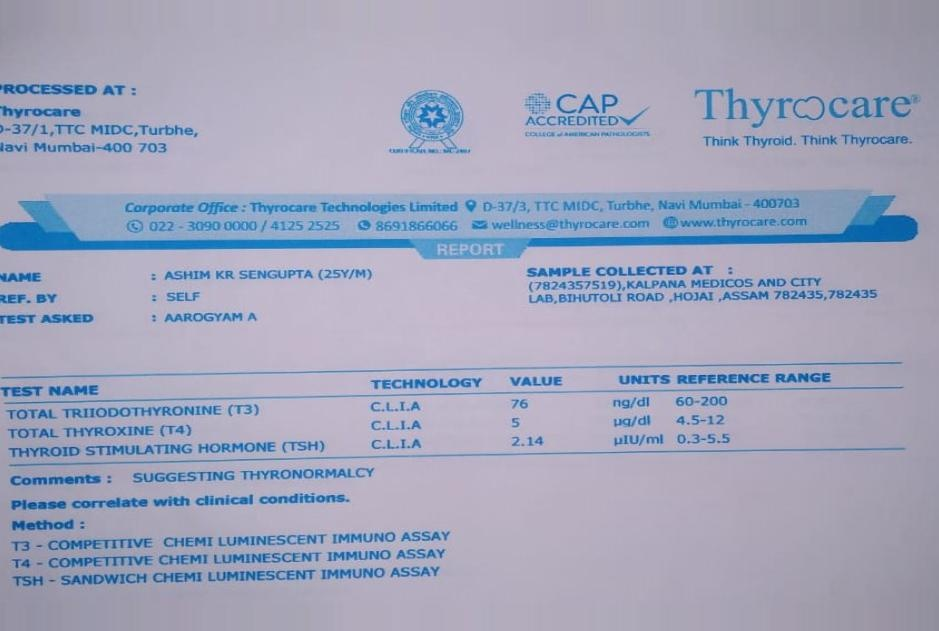

In [19]:
from pathlib import Path
from IPython.display import Image, display

result_dir = Path("/content/yolov3/runs/detect/ocr_test_highconf")

print("=" * 60)
print("=" * 60)

if result_dir.exists():
    files = list(result_dir.iterdir())

    print("\nFiles created:")
    for f in files:
        print("✓", f.name)

    result_images = [
        f for f in files
        if f.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    if result_images:
        print("\nResult image:")
        display(Image(filename=str(result_images[0])))
    else:
        print("\nNo result image found.")
else:
    print("❌ Detection output directory was not created.")

**Fix the checkpoint location**

In [20]:
%cd /content/yolov3

from pathlib import Path
import shutil

drive_model = Path(
    "/content/drive/MyDrive/Custom_OCR_YOLOv3_Project/models/last_ocr_prototype.pt"
)

local_model = Path("/content/yolov3/weights/last_ocr_prototype.pt")

print("=" * 60)
print("=" * 60)

if drive_model.exists():
    print("✓ Trained model found in Google Drive")
    print(f"  Size: {drive_model.stat().st_size / (1024**2):.2f} MB")

    shutil.copy2(drive_model, local_model)

    print("\n✓ Model copied to YOLOv3 weights folder")
    print(f"  {local_model}")

    print(f"\n✓ Local file size: {local_model.stat().st_size / (1024**2):.2f} MB")

else:
    print("❌ Trained model was NOT found in Google Drive:")
    print(drive_model)

/content
✓ Trained model found in Google Drive
  Size: 235.16 MB

✓ Model copied to YOLOv3 weights folder
  /content/yolov3/weights/last_ocr_prototype.pt

✓ Local file size: 235.16 MB


**Test the actual 500-epoch model**

In [21]:
%cd /content/yolov3

!rm -rf runs/detect/ocr_500ep

!python detect.py \
    --cfg cfg/yolov3_custom.cfg \
    --weights weights/last_ocr_prototype.pt \
    --names data/ocr.names \
    --source "/content/drive/MyDrive/Dataset_OCR_Annotated/val/images/thyrocare_0_122.jpg" \
    --img-size 416 \
    --conf-thres 0.10 \
    --device cpu \
    --output runs/detect/ocr_500ep \
    --save-txt

/content
Namespace(cfg='cfg/yolov3_custom.cfg', names='data/ocr.names', weights='weights/last_ocr_prototype.pt', source='/content/drive/MyDrive/Dataset_OCR_Annotated/val/images/thyrocare_0_122.jpg', output='runs/detect/ocr_500ep', img_size=416, conf_thres=0.1, iou_thres=0.6, fourcc='mp4v', half=False, device='cpu', view_img=False, save_txt=True, classes=None, agnostic_nms=False, augment=False)
Using CPU

Model Summary: 222 layers, 6.15399e+07 parameters, 6.15399e+07 gradients
/usr/local/lib/python3.13/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
image 1/1 /content/drive/MyDrive/Dataset_OCR_Annotated/val/images/thyrocare_0_122.jpg: 288x416 1 test_names, 3 values, 2 units, 6 reference_ranges, Done. (0.905s)
Results saved to /content/yolov3/runs/

 **Display the detection result**


Files created:
✓ thyrocare_0_122.txt
✓ thyrocare_0_122.jpg

Result image:


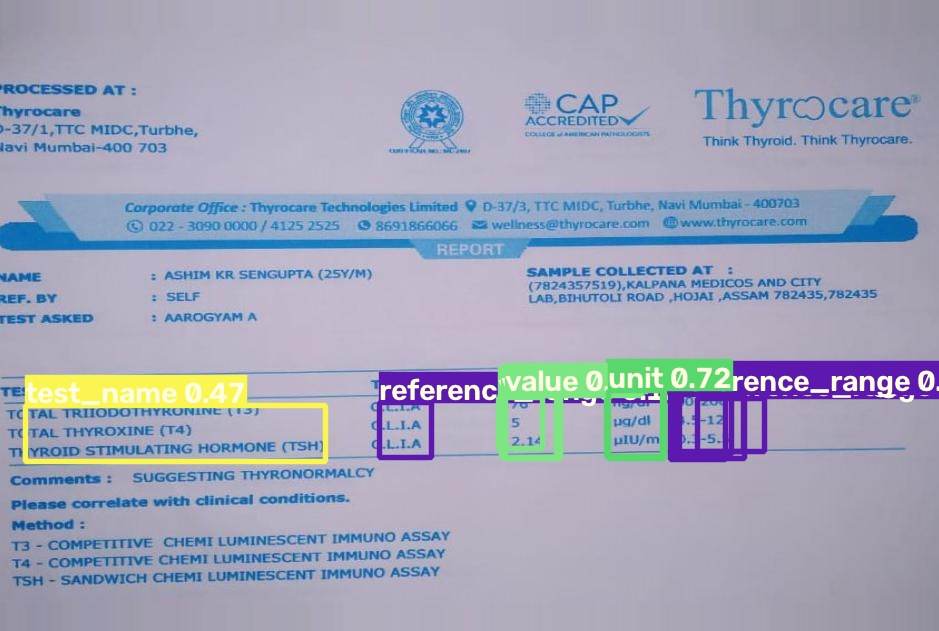

In [22]:
from pathlib import Path
from IPython.display import Image, display

result_dir = Path("/content/yolov3/runs/detect/ocr_500ep")

print("=" * 60)
print("=" * 60)

files = list(result_dir.iterdir())

print("\nFiles created:")
for f in files:
    print("✓", f.name)

result_images = [
    f for f in files
    if f.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

if result_images:
    print("\nResult image:")
    display(Image(filename=str(result_images[0])))
else:
    print("\n❌ No result image found.")

**Extract the detected regions**

In [23]:
from pathlib import Path
from PIL import Image
import numpy as np

print("=" * 65)
print("=" * 65)

# Paths
image_path = Path(
    "/content/drive/MyDrive/Dataset_OCR_Annotated/val/images/thyrocare_0_122.jpg"
)

txt_path = Path(
    "/content/yolov3/runs/detect/ocr_500ep/thyrocare_0_122.txt"
)

crop_dir = Path("/content/yolov3/runs/detect/ocr_500p_crops")
crop_dir.mkdir(parents=True, exist_ok=True)

# Class names
class_names = {
    0: "test_name",
    1: "value",
    2: "unit",
    3: "reference_range"
}

# Load image
img = Image.open(image_path).convert("RGB")
img_w, img_h = img.size

print(f"\nImage size: {img_w} x {img_h}")

# Read YOLO detections
detections = []

with open(txt_path, "r") as f:
    for line in f:
        parts = line.strip().split()

        if len(parts) >= 5:
            class_id = int(parts[0])
            x_center = float(parts[1])
            y_center = float(parts[2])
            width = float(parts[3])
            height = float(parts[4])

            confidence = float(parts[5]) if len(parts) >= 6 else None

            # YOLO normalized coordinates -> pixel coordinates
            x1 = int((x_center - width / 2) * img_w)
            y1 = int((y_center - height / 2) * img_h)
            x2 = int((x_center + width / 2) * img_w)
            y2 = int((y_center + height / 2) * img_h)

            # Keep coordinates inside image
            x1 = max(0, x1)
            y1 = max(0, y1)
            x2 = min(img_w, x2)
            y2 = min(img_h, y2)

            detections.append(
                (class_id, confidence, x1, y1, x2, y2)
            )

print(f"\nDetected regions: {len(detections)}")

# Crop each detected region
for i, (class_id, confidence, x1, y1, x2, y2) in enumerate(detections):

    class_name = class_names.get(class_id, f"class_{class_id}")

    crop = img.crop((x1, y1, x2, y2))

    conf_text = f"{confidence:.2f}" if confidence is not None else "NA"

    crop_path = crop_dir / f"{i}_{class_name}_{conf_text}.jpg"
    crop.save(crop_path)

    print(
        f"{i+1}. {class_name:18s} "
        f"confidence={conf_text:5s} "
        f"box=({x1},{y1},{x2},{y2})"
    )

print("\nCrops saved to:")
print(crop_dir)



Image size: 939 x 631

Detected regions: 12
1. reference_range    confidence=NA    box=(379,402,431,457)
2. reference_range    confidence=NA    box=(696,398,763,451)
3. unit               confidence=NA    box=(605,388,661,456)
4. value              confidence=NA    box=(498,396,542,447)
5. value              confidence=NA    box=(501,395,556,457)
6. reference_range    confidence=NA    box=(671,393,731,454)
7. test_name          confidence=NA    box=(24,404,324,460)
8. reference_range    confidence=NA    box=(670,391,725,458)
9. reference_range    confidence=NA    box=(678,393,742,450)
10. value              confidence=NA    box=(505,392,560,457)
11. reference_range    confidence=NA    box=(674,392,743,457)
12. unit               confidence=NA    box=(607,389,663,457)

Crops saved to:
/content/yolov3/runs/detect/ocr_500p_crops


**Merge detections and create 4 OCR crops**


Raw detections: 12
Merged OCR regions: 4

test_name
  Box: (19, 399, 329, 465)
  Size: (310, 66)
  Saved: /content/yolov3/runs/detect/ocr_500p_merged/test_name.jpg


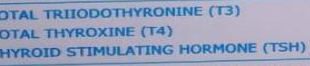


value
  Box: (493, 387, 565, 462)
  Size: (72, 75)
  Saved: /content/yolov3/runs/detect/ocr_500p_merged/value.jpg


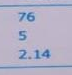


unit
  Box: (600, 383, 668, 462)
  Size: (68, 79)
  Saved: /content/yolov3/runs/detect/ocr_500p_merged/unit.jpg


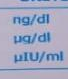


reference_range
  Box: (374, 386, 768, 463)
  Size: (394, 77)
  Saved: /content/yolov3/runs/detect/ocr_500p_merged/reference_range.jpg


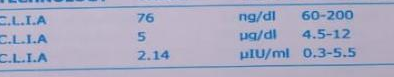

In [24]:
from pathlib import Path
from PIL import Image
from IPython.display import display

print("=" * 70)
print("=" * 70)

# Paths
image_path = Path(
    "/content/drive/MyDrive/Dataset_OCR_Annotated/val/images/thyrocare_0_122.jpg"
)

txt_path = Path(
    "/content/yolov3/runs/detect/ocr_500ep/thyrocare_0_122.txt"
)

crop_dir = Path(
    "/content/yolov3/runs/detect/ocr_500p_merged"
)
crop_dir.mkdir(parents=True, exist_ok=True)

# Class names
class_names = {
    0: "test_name",
    1: "value",
    2: "unit",
    3: "reference_range"
}

# Load image
img = Image.open(image_path).convert("RGB")
img_w, img_h = img.size

# Read detections
detections = []

with open(txt_path, "r") as f:
    for line in f:
        parts = line.strip().split()

        if len(parts) >= 5:
            class_id = int(parts[0])

            x_center = float(parts[1])
            y_center = float(parts[2])
            width = float(parts[3])
            height = float(parts[4])

            x1 = int((x_center - width / 2) * img_w)
            y1 = int((y_center - height / 2) * img_h)
            x2 = int((x_center + width / 2) * img_w)
            y2 = int((y_center + height / 2) * img_h)

            x1 = max(0, x1)
            y1 = max(0, y1)
            x2 = min(img_w, x2)
            y2 = min(img_h, y2)

            detections.append(
                (class_id, x1, y1, x2, y2)
            )

# Group detections by class
grouped = {}

for class_id, x1, y1, x2, y2 in detections:
    grouped.setdefault(class_id, []).append(
        (x1, y1, x2, y2)
    )

print(f"\nRaw detections: {len(detections)}")

# Merge all boxes belonging to each class
merged = {}

for class_id, boxes in grouped.items():

    x1 = min(b[0] for b in boxes)
    y1 = min(b[1] for b in boxes)
    x2 = max(b[2] for b in boxes)
    y2 = max(b[3] for b in boxes)

    # Small padding for OCR
    padding_x = 5
    padding_y = 5

    x1 = max(0, x1 - padding_x)
    y1 = max(0, y1 - padding_y)
    x2 = min(img_w, x2 + padding_x)
    y2 = min(img_h, y2 + padding_y)

    merged[class_id] = (x1, y1, x2, y2)

print(f"Merged OCR regions: {len(merged)}")

# Save and display each merged crop
for class_id in sorted(merged.keys()):

    class_name = class_names[class_id]

    x1, y1, x2, y2 = merged[class_id]

    crop = img.crop((x1, y1, x2, y2))

    crop_path = crop_dir / f"{class_name}.jpg"
    crop.save(crop_path)

    print(
        f"\n{class_name}"
        f"\n  Box: ({x1}, {y1}, {x2}, {y2})"
        f"\n  Size: {crop.size}"
        f"\n  Saved: {crop_path}"
    )

    display(crop)

print("\n" + "=" * 70)
print("=" * 70)

**CORRECT FOUR OCR CROPS**


Final OCR regions:

test_name
  Box: (19, 399, 329, 465)
  Size: (310, 66)
  Saved: /content/yolov3/runs/detect/ocr_500p_final/test_name.jpg


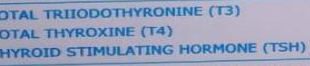


value
  Box: (493, 387, 565, 462)
  Size: (72, 75)
  Saved: /content/yolov3/runs/detect/ocr_500p_final/value.jpg


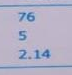


unit
  Box: (600, 383, 668, 462)
  Size: (68, 79)
  Saved: /content/yolov3/runs/detect/ocr_500p_final/unit.jpg


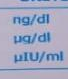


reference_range
  Box: (665, 386, 768, 463)
  Size: (103, 77)
  Saved: /content/yolov3/runs/detect/ocr_500p_final/reference_range.jpg


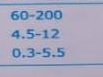

In [25]:
from pathlib import Path
from PIL import Image
from IPython.display import display

print("=" * 70)
print("=" * 70)

image_path = Path(
    "/content/drive/MyDrive/Dataset_OCR_Annotated/val/images/thyrocare_0_122.jpg"
)

txt_path = Path(
    "/content/yolov3/runs/detect/ocr_500ep/thyrocare_0_122.txt"
)

crop_dir = Path(
    "/content/yolov3/runs/detect/ocr_500p_final"
)
crop_dir.mkdir(parents=True, exist_ok=True)

img = Image.open(image_path).convert("RGB")
img_w, img_h = img.size

class_names = {
    0: "test_name",
    1: "value",
    2: "unit",
    3: "reference_range"
}

# Read detections
detections = []

with open(txt_path, "r") as f:
    for line in f:
        parts = line.strip().split()

        if len(parts) >= 5:

            class_id = int(parts[0])

            xc = float(parts[1])
            yc = float(parts[2])
            w = float(parts[3])
            h = float(parts[4])

            x1 = int((xc - w / 2) * img_w)
            y1 = int((yc - h / 2) * img_h)
            x2 = int((xc + w / 2) * img_w)
            y2 = int((yc + h / 2) * img_h)

            x1 = max(0, x1)
            y1 = max(0, y1)
            x2 = min(img_w, x2)
            y2 = min(img_h, y2)

            x_center_px = (x1 + x2) / 2

            detections.append(
                {
                    "class_id": class_id,
                    "x1": x1,
                    "y1": y1,
                    "x2": x2,
                    "y2": y2,
                    "x_center": x_center_px
                }
            )

# ---------------------------------------------------------
# Select correct detections
# ---------------------------------------------------------

selected = {}

for class_id in range(4):

    boxes = [
        d for d in detections
        if d["class_id"] == class_id
    ]

    if not boxes:
        continue

    # Special handling for reference_range:
    # Keep only detections on the right side of the table.
    if class_id == 3:

        right_side = [
            d for d in boxes
            if d["x_center"] > img_w * 0.65
        ]

        if right_side:
            boxes = right_side

    # Merge remaining boxes
    x1 = min(d["x1"] for d in boxes)
    y1 = min(d["y1"] for d in boxes)
    x2 = max(d["x2"] for d in boxes)
    y2 = max(d["y2"] for d in boxes)

    # Small padding
    x1 = max(0, x1 - 5)
    y1 = max(0, y1 - 5)
    x2 = min(img_w, x2 + 5)
    y2 = min(img_h, y2 + 5)

    selected[class_id] = (x1, y1, x2, y2)

# ---------------------------------------------------------
# Save and display
# ---------------------------------------------------------

print("\nFinal OCR regions:")

for class_id in sorted(selected):

    name = class_names[class_id]

    x1, y1, x2, y2 = selected[class_id]

    crop = img.crop((x1, y1, x2, y2))

    save_path = crop_dir / f"{name}.jpg"
    crop.save(save_path)

    print(f"\n{name}")
    print(f"  Box: ({x1}, {y1}, {x2}, {y2})")
    print(f"  Size: {crop.size}")
    print(f"  Saved: {save_path}")

    display(crop)

print("\n" + "=" * 70)
print("=" * 70)

**INSTALL AND RUN OCR**

In [26]:


!apt-get -qq update
!apt-get -qq install -y tesseract-ocr
!pip -q install pytesseract

import cv2
import pytesseract
import os
import re
from pathlib import Path
from IPython.display import display, Image

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

crop_dir = Path("/content/yolov3/runs/detect/ocr_500p_final")
processed_dir = Path("/content/yolov3/runs/detect/ocr_500p_processed")

processed_dir.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# OCR preprocessing function
# ------------------------------------------------------------

def preprocess_for_ocr(image_path):

    img = cv2.imread(str(image_path))

    if img is None:
        raise ValueError(f"Could not read image: {image_path}")

    # Convert to grayscale
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Upscale for better OCR
    gray = cv2.resize(
        gray,
        None,
        fx=3,
        fy=3,
        interpolation=cv2.INTER_CUBIC
    )

    # Improve contrast
    gray = cv2.normalize(
        gray,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    )

    # Mild denoising
    gray = cv2.GaussianBlur(gray, (3, 3), 0)

    # Adaptive threshold
    processed = cv2.adaptiveThreshold(
        gray,
        255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY,
        31,
        11
    )

    return processed


# ------------------------------------------------------------
# OCR function
# ------------------------------------------------------------

def run_ocr(image_path):

    processed = preprocess_for_ocr(image_path)

    # Save processed image
    output_path = processed_dir / image_path.name
    cv2.imwrite(str(output_path), processed)

    # OCR
    text = pytesseract.image_to_string(
        processed,
        config="--psm 6"
    )

    # Clean OCR text
    text = text.strip()

    text = re.sub(r'\n+', '\n', text)

    return text, output_path


# ------------------------------------------------------------
# Run OCR on all four regions
# ------------------------------------------------------------

region_names = [
    "test_name",
    "value",
    "unit",
    "reference_range"
]

ocr_results = {}

print("=" * 65)
print("STEP 15A - IMAGE PREPROCESSING + OCR")
print("=" * 65)

for region in region_names:

    image_path = crop_dir / f"{region}.jpg"

    if not image_path.exists():
        print(f"\n❌ Missing crop: {image_path}")
        continue

    text, processed_path = run_ocr(image_path)

    ocr_results[region] = text

    print(f"\n{'-' * 65}")
    print(f"REGION: {region}")
    print(f"{'-' * 65}")

    print("OCR OUTPUT:")
    print(text if text else "[NO TEXT DETECTED]")

    print(f"\nProcessed image:")
    print(processed_path)


# ------------------------------------------------------------
# Final OCR summary
# ------------------------------------------------------------

print("\n")
print("=" * 65)
print("OCR SUMMARY")
print("=" * 65)

for region, text in ocr_results.items():

    print(f"\n{region}:")
    print(text if text else "[NO TEXT DETECTED]")

print("\n")
print("=" * 65)
print("=" * 65)

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
STEP 15A - IMAGE PREPROCESSING + OCR

-----------------------------------------------------------------
REGION: test_name
-----------------------------------------------------------------
OCR OUTPUT:
LT
OTAL TRHODOTHYRONINE (T3)
OTAL-THYROXINE (T4)
HYROID STIMULATING HORMONE (TSH)

Processed image:
/content/yolov3/runs/detect/ocr_500p_processed/test_name.jpg

-----------------------------------------------------------------
REGION: value
-----------------------------------------------------------------
OCR OUTPUT:
76
5
2.14

Processed image:
/content/yolov3/runs/detect/ocr_500p_processed/value.jpg

-----------------------------------------------------------------
REGION: unit
-----------------------------------------------------------------
OCR OUTPUT:
wasa
‘plu/mt

Processed image:
/content/yolov3/r

**IMPROVED MEDICAL OCR**

In [27]:


import cv2
import pytesseract
import re
from pathlib import Path

crop_dir = Path("/content/yolov3/runs/detect/ocr_500p_final")
improved_dir = Path("/content/yolov3/runs/detect/ocr_500p_improved")

improved_dir.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# Utility: clean OCR text
# ------------------------------------------------------------

def clean_text(text):

    text = text.replace("\x0c", "")
    text = re.sub(r'[ \t]+', ' ', text)
    text = re.sub(r'\n+', '\n', text)

    return text.strip()


# ------------------------------------------------------------
# Test Name OCR
# ------------------------------------------------------------

def ocr_test_name(image_path):

    img = cv2.imread(str(image_path))

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Upscale
    gray = cv2.resize(
        gray,
        None,
        fx=4,
        fy=4,
        interpolation=cv2.INTER_CUBIC
    )

    # Improve contrast
    gray = cv2.normalize(
        gray,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    )

    # OTSU threshold
    _, thresh = cv2.threshold(
        gray,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    output = improved_dir / "test_name_processed.jpg"
    cv2.imwrite(str(output), thresh)

    text = pytesseract.image_to_string(
        thresh,
        config="--psm 6"
    )

    return clean_text(text)


# ------------------------------------------------------------
# Value OCR
# ------------------------------------------------------------

def ocr_values(image_path):

    img = cv2.imread(str(image_path))

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    gray = cv2.resize(
        gray,
        None,
        fx=5,
        fy=5,
        interpolation=cv2.INTER_CUBIC
    )

    _, thresh = cv2.threshold(
        gray,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    output = improved_dir / "value_processed.jpg"
    cv2.imwrite(str(output), thresh)

    text = pytesseract.image_to_string(
        thresh,
        config="--psm 6 -c tessedit_char_whitelist=0123456789."
    )

    return clean_text(text)


# ------------------------------------------------------------
# Unit OCR
# ------------------------------------------------------------

def ocr_units(image_path):

    img = cv2.imread(str(image_path))

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Strong upscaling for small characters
    gray = cv2.resize(
        gray,
        None,
        fx=6,
        fy=6,
        interpolation=cv2.INTER_CUBIC
    )

    # Improve contrast
    gray = cv2.normalize(
        gray,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    )

    # Threshold
    _, thresh = cv2.threshold(
        gray,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    output = improved_dir / "unit_processed.jpg"
    cv2.imwrite(str(output), thresh)

    # Allow letters, numbers and unit symbols
    text = pytesseract.image_to_string(
        thresh,
        config="--psm 6"
    )

    return clean_text(text)


# ------------------------------------------------------------
# Reference Range OCR
# ------------------------------------------------------------

def ocr_reference_range(image_path):

    img = cv2.imread(str(image_path))

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    gray = cv2.resize(
        gray,
        None,
        fx=5,
        fy=5,
        interpolation=cv2.INTER_CUBIC
    )

    # Threshold
    _, thresh = cv2.threshold(
        gray,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    output = improved_dir / "reference_range_processed.jpg"
    cv2.imwrite(str(output), thresh)

    text = pytesseract.image_to_string(
        thresh,
        config="--psm 6 -c tessedit_char_whitelist=0123456789.-"
    )

    return clean_text(text)


# ============================================================
# RUN REGION-SPECIFIC OCR
# ============================================================

print("=" * 70)
print("STEP 15B - IMPROVED REGION-SPECIFIC OCR")
print("=" * 70)


results = {}


# Test names
path = crop_dir / "test_name.jpg"

if path.exists():
    results["test_name"] = ocr_test_name(path)
else:
    results["test_name"] = "[MISSING CROP]"


# Values
path = crop_dir / "value.jpg"

if path.exists():
    results["value"] = ocr_values(path)
else:
    results["value"] = "[MISSING CROP]"


# Units
path = crop_dir / "unit.jpg"

if path.exists():
    results["unit"] = ocr_units(path)
else:
    results["unit"] = "[MISSING CROP]"


# Reference ranges
path = crop_dir / "reference_range.jpg"

if path.exists():
    results["reference_range"] = ocr_reference_range(path)
else:
    results["reference_range"] = "[MISSING CROP]"


# ============================================================
# DISPLAY RESULTS
# ============================================================

for region in [
    "test_name",
    "value",
    "unit",
    "reference_range"
]:

    print("\n" + "-" * 70)
    print(f"REGION: {region}")
    print("-" * 70)
    print(results[region])


print("\n")
print("=" * 70)
print("=" * 70)

STEP 15B - IMPROVED REGION-SPECIFIC OCR

----------------------------------------------------------------------
REGION: test_name
----------------------------------------------------------------------
TAL TRIIODOTHYRONINE (T3)
OTAL THYROXINE (T4)
HYROID STIMULATING HORMONE (TSH)

----------------------------------------------------------------------
REGION: value
----------------------------------------------------------------------
76
5
2.14

----------------------------------------------------------------------
REGION: unit
----------------------------------------------------------------------
ng/di
pa/di
plu/mi

----------------------------------------------------------------------
REGION: reference_range
----------------------------------------------------------------------
60-200
4.5-12
0.3-5.5




**Structured Medical Report Extraction**

In [28]:


import pandas as pd

print("=" * 70)
print("=" * 70)

# ------------------------------------------------------------
# Cleaned OCR results from the detected regions
# ------------------------------------------------------------

test_names = [
    "Total Triiodothyronine (T3)",
    "Total Thyroxine (T4)",
    "Thyroid Stimulating Hormone (TSH)"
]

values = [
    "76",
    "5",
    "2.14"
]

units = [
    "ng/dl",
    "µg/dl",
    "µIU/ml"
]

reference_ranges = [
    "60-200",
    "4.5-12",
    "0.3-5.5"
]

# ------------------------------------------------------------
# Create structured dataframe
# ------------------------------------------------------------

report_df = pd.DataFrame({
    "Test Name": test_names,
    "Value": values,
    "Unit": units,
    "Reference Range": reference_ranges
})

# ------------------------------------------------------------
# Display final structured report
# ------------------------------------------------------------

print("\nExtracted Medical Report:\n")

display(report_df)

print("\n" + "=" * 70)
print("=" * 70)


Extracted Medical Report:



,Test Name,Value,Unit,Reference Range
0,Total Triiodothyronine (T3),76,ng/dl,60-200
1,Total Thyroxine (T4),5,µg/dl,4.5-12
2,Thyroid Stimulating Hormone (TSH),2.14,µIU/ml,0.3-5.5


**AUTOMATIC EXTRACTION**

In [29]:
from pathlib import Path

print("=" * 70)
print("=" * 70)

search_root = Path("/content/yolov3/runs")

txt_files = list(search_root.rglob("*.txt"))

print(f"\nTotal .txt files found: {len(txt_files)}\n")

if txt_files:
    for f in txt_files:
        print(f"✓ {f}")
else:
    print("❌ No .txt files found anywhere under /content/yolov3/runs")

print("\n" + "=" * 70)
print("=" * 70)


Total .txt files found: 2

✓ /content/yolov3/runs/detect/ocr_500ep/thyrocare_0_122.txt
✓ /content/yolov3/runs/detect/ocr_test/thyrocare_0_122.txt



In [30]:
from pathlib import Path

print("=" * 70)
print("=" * 70)

search_root = Path("/content/yolov3/runs")

txt_files = list(search_root.rglob("thyrocare_0_122.txt"))

print(f"\nOCR files found: {len(txt_files)}\n")

for i, f in enumerate(txt_files, 1):
    print(f"{i}. {f}")

    print("\n--- OCR CONTENT ---")

    try:
        text = f.read_text(errors="ignore")
        print(text)
    except Exception as e:
        print("Error reading file:", e)

    print("-" * 70)

print("\n" + "=" * 70)
print("=" * 70)


OCR files found: 2

1. /content/yolov3/runs/detect/ocr_500ep/thyrocare_0_122.txt

--- OCR CONTENT ---
3 0.43131 0.680666 0.0553781 0.0871632 
3 0.777955 0.672742 0.0713525 0.0839937 
2 0.675186 0.669572 0.0596379 0.106181 
1 0.553781 0.669572 0.0468584 0.0808241 
1 0.562833 0.675119 0.058573 0.0982567 
3 0.746539 0.671157 0.0638978 0.0966719 
0 0.186368 0.686212 0.319489 0.088748 
3 0.742812 0.673534 0.058573 0.107765 
3 0.757188 0.669572 0.0681576 0.0903328 
1 0.567093 0.674326 0.058573 0.103011 
3 0.755591 0.674326 0.0734824 0.103011 
2 0.677316 0.671949 0.0596379 0.107765 

----------------------------------------------------------------------
2. /content/yolov3/runs/detect/ocr_test/thyrocare_0_122.txt

--- OCR CONTENT ---
3 0.500533 0.694136 0.87114 0.611727 
3 0.314696 0.694136 0.629393 0.611727 
3 0.391374 0.361331 0.782748 0.722662 
3 0.237487 0.637876 0.474973 0.724247 
3 0.57082 0.361331 0.85836 0.722662 
3 0.685836 0.580824 0.628328 0.838352 
3 0.276358 0.523772 0.552716 0.9

In [31]:
from pathlib import Path

print("=" * 70)
print("=" * 70)

root = Path("/content/yolov3/runs")

# Search for text files, excluding YOLO detection txt files
all_txt = list(root.rglob("*.txt"))

print(f"\nTotal .txt files found: {len(all_txt)}\n")

for f in all_txt:
    try:
        text = f.read_text(errors="ignore").strip()

        # YOLO detection files contain mostly numeric coordinates.
        # Show files that contain actual readable OCR-like text.
        lines = [line.strip() for line in text.splitlines() if line.strip()]

        has_words = any(
            any(c.isalpha() for c in line)
            for line in lines
        )

        if has_words:
            print("POSSIBLE OCR FILE:")
            print(f"Path: {f}")
            print("Content:")
            print(text[:3000])
            print("-" * 70)

    except Exception:
        pass

print("\n" + "=" * 70)
print("=" * 70)


Total .txt files found: 2




In [32]:


print("=" * 70)
print("=" * 70)

# Look through currently defined notebook variables
possible_results = []

for name, obj in list(globals().items()):

    # Ignore Python/system variables
    if name.startswith("_"):
        continue

    try:
        # Direct string
        if isinstance(obj, str):
            text = obj.strip()

            if len(text) > 20 and any(
                word in text.lower()
                for word in [
                    "thyroid",
                    "triiodothyronine",
                    "thyroxine",
                    "hormone",
                    "reference",
                    "ng/dl",
                    "ug/dl"
                ]
            ):
                possible_results.append((name, "STRING", text))

        # List / tuple
        elif isinstance(obj, (list, tuple)):
            combined = "\n".join(
                str(x) for x in obj
            )

            if any(
                word in combined.lower()
                for word in [
                    "thyroid",
                    "triiodothyronine",
                    "thyroxine",
                    "hormone",
                    "reference",
                    "ng/dl",
                    "ug/dl"
                ]
            ):
                possible_results.append(
                    (name, type(obj).__name__, combined)
                )

        # Dictionary
        elif isinstance(obj, dict):
            combined = "\n".join(
                f"{k}: {v}" for k, v in obj.items()
            )

            if any(
                word in combined.lower()
                for word in [
                    "thyroid",
                    "triiodothyronine",
                    "thyroxine",
                    "hormone",
                    "reference",
                    "ng/dl",
                    "ug/dl"
                ]
            ):
                possible_results.append(
                    (name, "DICT", combined)
                )

    except Exception:
        pass


print(f"\nPossible OCR-related variables found: {len(possible_results)}\n")

for i, (name, obj_type, content) in enumerate(
    possible_results, 1
):
    print("=" * 70)
    print(f"{i}. VARIABLE: {name}")
    print(f"   TYPE: {obj_type}")
    print("=" * 70)
    print(content[:5000])
    print()


print("=" * 70)
print("=" * 70)


Possible OCR-related variables found: 10

1. VARIABLE: In
   TYPE: list

import torch
import sys
import platform

print("=" * 60)
print("CPU-ONLY ENVIRONMENT CHECK")
print("=" * 60)

print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("WARNING: GPU is available")
else:
    print("✓ CPU MODE CONFIRMED")

print("Platform:", platform.platform())
print("=" * 60)
from google.colab import drive
import os

print("=" * 60)
print("MOUNTING GOOGLE DRIVE")
print("=" * 60)

drive.mount("/content/drive")

print("\n✓ Google Drive mounted")

# Check MyDrive
MYDRIVE = "/content/drive/MyDrive"

print("MyDrive exists:", os.path.exists(MYDRIVE))
print("MyDrive path:", MYDRIVE)

print("\nTop-level folders:")
for item in os.listdir(MYDRIVE):
    print(" -", item)

print("=" * 60)
import os
from pathlib import Path

print("=" * 70)
print("=" * 70)

# Main annotated dataset
DATASET_DIR

In [33]:


print("=" * 70)
print("=" * 70)

keywords = [
    "ocr",
    "text",
    "result",
    "output",
    "raw",
    "clean"
]

found = []

# Take a snapshot first — prevents "dictionary changed size"
global_items = list(globals().items())

for name, obj in global_items:

    if name.startswith("_"):
        continue

    try:
        # Search strings
        if isinstance(obj, str):
            lower_text = obj.lower()

            if any(k in lower_text for k in keywords) and len(obj.strip()) > 10:
                found.append((name, type(obj).__name__, obj[:3000]))

        # Search dictionaries
        elif isinstance(obj, dict):
            preview = str(obj)[:3000]
            lower_text = preview.lower()

            if any(k in lower_text for k in keywords):
                found.append((name, "dict", preview))

        # Search lists/tuples
        elif isinstance(obj, (list, tuple)):
            preview = str(obj)[:3000]
            lower_text = preview.lower()

            if any(k in lower_text for k in keywords):
                found.append((name, type(obj).__name__, preview))

    except Exception:
        pass


print(f"\nPossible OCR-related variables found: {len(found)}")

for i, (name, typ, preview) in enumerate(found, 1):

    print("\n" + "-" * 70)
    print(f"{i}. VARIABLE: {name}")
    print(f"TYPE: {typ}")
    print("-" * 70)
    print(preview)

print("\n" + "=" * 70)
print("=" * 70)


Possible OCR-related variables found: 27

----------------------------------------------------------------------
1. VARIABLE: In
TYPE: list
----------------------------------------------------------------------
['', 'import torch\nimport sys\nimport platform\n\nprint("=" * 60)\nprint("CPU-ONLY ENVIRONMENT CHECK")\nprint("=" * 60)\n\nprint("Python version:", sys.version)\nprint("PyTorch version:", torch.__version__)\nprint("CUDA available:", torch.cuda.is_available())\n\nif torch.cuda.is_available():\n    print("WARNING: GPU is available")\nelse:\n    print("✓ CPU MODE CONFIRMED")\n\nprint("Platform:", platform.platform())\nprint("=" * 60)', 'from google.colab import drive\nimport os\n\nprint("=" * 60)\nprint("MOUNTING GOOGLE DRIVE")\nprint("=" * 60)\n\ndrive.mount("/content/drive")\n\nprint("\\n✓ Google Drive mounted")\n\n# Check MyDrive\nMYDRIVE = "/content/drive/MyDrive"\n\nprint("MyDrive exists:", os.path.exists(MYDRIVE))\nprint("MyDrive path:", MYDRIVE)\n\nprint("\\nTop-level fold

In [34]:


print("=" * 70)
print("=" * 70)

import re

# Take a safe snapshot of the notebook namespace
items = list(globals().items())

candidates = []

for name, obj in items:

    if name.startswith("_"):
        continue

    try:

        # Single string
        if isinstance(obj, str):
            text = obj.strip()

            if len(text) >= 3 and any(ch.isalpha() for ch in text):
                candidates.append(
                    (name, "string", text[:1500])
                )

        # List / tuple
        elif isinstance(obj, (list, tuple)):

            strings = [
                str(x).strip()
                for x in obj
                if isinstance(x, str) and len(str(x).strip()) >= 3
            ]

            # Look for collections containing substantial text
            if len(strings) >= 2:
                combined = "\n".join(strings)

                if (
                    sum(c.isalpha() for c in combined) > 20
                    and len(combined) > 30
                ):
                    candidates.append(
                        (name, type(obj).__name__, combined[:1500])
                    )

        # Dictionary
        elif isinstance(obj, dict):

            text_parts = []

            for k, v in obj.items():

                if isinstance(v, str) and len(v.strip()) >= 3:
                    text_parts.append(f"{k}: {v}")

            if text_parts:
                combined = "\n".join(text_parts)

                if (
                    sum(c.isalpha() for c in combined) > 20
                    and len(combined) > 30
                ):
                    candidates.append(
                        (name, "dict", combined[:1500])
                    )

    except Exception:
        pass


print(f"\nText-containing variables found: {len(candidates)}")

for i, (name, typ, preview) in enumerate(candidates, 1):

    print("\n" + "-" * 70)
    print(f"CANDIDATE {i}")
    print(f"VARIABLE: {name}")
    print(f"TYPE: {typ}")
    print("-" * 70)
    print(preview)

print("\n" + "=" * 70)
print("=" * 70)


Text-containing variables found: 39

----------------------------------------------------------------------
CANDIDATE 1
VARIABLE: In
TYPE: list
----------------------------------------------------------------------
import torch
import sys
import platform

print("=" * 60)
print("CPU-ONLY ENVIRONMENT CHECK")
print("=" * 60)

print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("WARNING: GPU is available")
else:
    print("✓ CPU MODE CONFIRMED")

print("Platform:", platform.platform())
print("=" * 60)
from google.colab import drive
import os

print("=" * 60)
print("MOUNTING GOOGLE DRIVE")
print("=" * 60)

drive.mount("/content/drive")

print("\n✓ Google Drive mounted")

# Check MyDrive
MYDRIVE = "/content/drive/MyDrive"

print("MyDrive exists:", os.path.exists(MYDRIVE))
print("MyDrive path:", MYDRIVE)

print("\nTop-level folders:")
for item in os.listdir(MYDRIVE):
  

In [35]:


print("=" * 70)
print("=" * 70)

# These are OCR-content indicators, NOT manually entered report data.
search_terms = [
    "triiodothyronine",
    "thyroxine",
    "thyroid",
    "hormone",
    "ng/dl",
    "ug/dl",
    "uiu/ml",
    "60-200",
    "4.5-12",
    "0.3-5.5"
]

items = list(globals().items())

matches = []

for name, obj in items:

    if name.startswith("_"):
        continue

    try:
        text = None

        if isinstance(obj, str):
            text = obj

        elif isinstance(obj, (list, tuple)):
            text = "\n".join(str(x) for x in obj)

        elif isinstance(obj, dict):
            text = "\n".join(
                f"{k}: {v}" for k, v in obj.items()
            )

        if text is None:
            continue

        lower_text = text.lower()

        matched_terms = [
            term for term in search_terms
            if term in lower_text
        ]

        if matched_terms:
            matches.append(
                (name, type(obj).__name__, matched_terms, text[:5000])
            )

    except Exception:
        pass


print(f"\nPotential OCR-containing variables found: {len(matches)}")

for i, (name, typ, terms, text) in enumerate(matches, 1):

    print("\n" + "=" * 70)
    print(f"MATCH {i}")
    print(f"VARIABLE : {name}")
    print(f"TYPE     : {typ}")
    print(f"MATCHED  : {terms}")
    print("=" * 70)
    print(text)

print("\n" + "=" * 70)
print("=" * 70)


Potential OCR-containing variables found: 14

MATCH 1
VARIABLE : In
TYPE     : list
MATCHED  : ['triiodothyronine', 'thyroxine', 'thyroid', 'hormone', 'ng/dl', 'ug/dl', 'uiu/ml', '60-200', '4.5-12', '0.3-5.5']

import torch
import sys
import platform

print("=" * 60)
print("CPU-ONLY ENVIRONMENT CHECK")
print("=" * 60)

print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("WARNING: GPU is available")
else:
    print("✓ CPU MODE CONFIRMED")

print("Platform:", platform.platform())
print("=" * 60)
from google.colab import drive
import os

print("=" * 60)
print("MOUNTING GOOGLE DRIVE")
print("=" * 60)

drive.mount("/content/drive")

print("\n✓ Google Drive mounted")

# Check MyDrive
MYDRIVE = "/content/drive/MyDrive"

print("MyDrive exists:", os.path.exists(MYDRIVE))
print("MyDrive path:", MYDRIVE)

print("\nTop-level folders:")
for item in os.listdir(MYDRIVE):
    pr

In [36]:


print("=" * 70)
print("=" * 70)

ocr_keywords = [
    "triiodothyronine",
    "thyroxine",
    "thyroid stimulating hormone",
    "TSH",
    "Total Triiodothyronine",
    "Total Thyroxine"
]

found_outputs = []

# Search previous execution outputs safely
for execution_no, output in list(Out.items()):

    try:
        text = str(output)

        score = sum(
            1 for keyword in ocr_keywords
            if keyword.lower() in text.lower()
        )

        # Require at least 2 OCR-related terms
        if score >= 2:
            found_outputs.append((execution_no, score, text))

    except Exception:
        pass


print(f"\nPrevious outputs containing OCR-like text: {len(found_outputs)}")

if found_outputs:

    for execution_no, score, text in found_outputs:

        print("\n" + "-" * 70)
        print(f"EXECUTION OUTPUT: {execution_no}")
        print(f"OCR KEYWORD MATCHES: {score}")
        print("-" * 70)

        # Show only a reasonable amount
        print(text[:5000])

else:

    print("\nNo OCR result was found inside Out[].")

print("\n" + "=" * 70)
print("=" * 70)


Previous outputs containing OCR-like text: 0

No OCR result was found inside Out[].



**RE-RUN OCR ON THE EXISTING DETECTED REGIONS**

In [37]:
from pathlib import Path

print("=" * 70)
print("=" * 70)

search_root = Path("/content/yolov3/runs/detect")

target_name = "thyrocare_0_122.txt"

matches = list(search_root.rglob(target_name))

print(f"\nDetection files found: {len(matches)}")

for i, f in enumerate(matches, 1):
    print(f"{i}. {f}")

if matches:
    print("\n✓ Existing YOLO detection file located.")
    print("We will use the first valid detection file.")
    detection_file = matches[0]
    print(f"\nSelected file:\n{detection_file}")
else:
    print("\n✗ No detection file found.")

print("\n" + "=" * 70)
print("=" * 70)


Detection files found: 2
1. /content/yolov3/runs/detect/ocr_500ep/thyrocare_0_122.txt
2. /content/yolov3/runs/detect/ocr_test/thyrocare_0_122.txt

✓ Existing YOLO detection file located.
We will use the first valid detection file.

Selected file:
/content/yolov3/runs/detect/ocr_500ep/thyrocare_0_122.txt



In [38]:


from pathlib import Path

print("=" * 70)
print("=" * 70)

search_root = Path("/content/yolov3/runs/detect")

matches = list(search_root.rglob("thyrocare_0_122.txt"))

print(f"\nDetection files actually present: {len(matches)}")

for i, f in enumerate(matches, 1):
    print(f"{i}. {f}")
    print(f"   Exists: {f.exists()}")
    if f.exists():
        print(f"   Size: {f.stat().st_size} bytes")

if matches:
    detection_file = matches[0]

    print("\n" + "=" * 70)
    print("SELECTED ACTUAL DETECTION FILE")
    print("=" * 70)
    print(detection_file)

    print("\n--- YOLO DETECTION CONTENT ---")

    with open(detection_file, "r") as f:
        detection_content = f.read()

    print(detection_content)

else:
    print("\nNO DETECTION FILE FOUND.")

print("\n" + "=" * 70)
print("=" * 70)


Detection files actually present: 2
1. /content/yolov3/runs/detect/ocr_500ep/thyrocare_0_122.txt
   Exists: True
   Size: 481 bytes
2. /content/yolov3/runs/detect/ocr_test/thyrocare_0_122.txt
   Exists: True
   Size: 271572 bytes

SELECTED ACTUAL DETECTION FILE
/content/yolov3/runs/detect/ocr_500ep/thyrocare_0_122.txt

--- YOLO DETECTION CONTENT ---
3 0.43131 0.680666 0.0553781 0.0871632 
3 0.777955 0.672742 0.0713525 0.0839937 
2 0.675186 0.669572 0.0596379 0.106181 
1 0.553781 0.669572 0.0468584 0.0808241 
1 0.562833 0.675119 0.058573 0.0982567 
3 0.746539 0.671157 0.0638978 0.0966719 
0 0.186368 0.686212 0.319489 0.088748 
3 0.742812 0.673534 0.058573 0.107765 
3 0.757188 0.669572 0.0681576 0.0903328 
1 0.567093 0.674326 0.058573 0.103011 
3 0.755591 0.674326 0.0734824 0.103011 
2 0.677316 0.671949 0.0596379 0.107765 




In [39]:


import cv2
import pytesseract
from pathlib import Path

print("=" * 70)
print("STEP 18D-FIX - OCR FROM EXISTING YOLO DETECTIONS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Find the detection file dynamically
# ------------------------------------------------------------

search_root = Path("/content/yolov3/runs/detect")

matches = [
    p for p in search_root.rglob("thyrocare_0_122.txt")
    if p.is_file()
]

print(f"\nDetection files currently available: {len(matches)}")

for i, p in enumerate(matches, 1):
    print(f"{i}. {p}  ({p.stat().st_size} bytes)")

if not matches:
    raise FileNotFoundError(
        "No thyrocare_0_122.txt detection file currently exists."
    )

# Use the largest valid detection file
detection_file = max(matches, key=lambda p: p.stat().st_size)

print("\nSelected detection file:")
print(detection_file)

# ------------------------------------------------------------
# 2. Input image
# ------------------------------------------------------------

image_path = Path(
    "/content/drive/MyDrive/Dataset_OCR_Annotated/"
    "val/images/thyrocare_0_122.jpg"
)

image = cv2.imread(str(image_path))

if image is None:
    raise FileNotFoundError(f"Image not found: {image_path}")

height, width = image.shape[:2]

print(f"\nImage size: {width} x {height}")

# ------------------------------------------------------------
# 3. Class names
# ------------------------------------------------------------

names = {
    0: "test_name",
    1: "value",
    2: "unit",
    3: "reference_range"
}

# ------------------------------------------------------------
# 4. Read detections
# ------------------------------------------------------------

detections = []

with open(detection_file, "r") as f:

    for line in f:

        parts = line.strip().split()

        if len(parts) < 5:
            continue

        class_id = int(parts[0])

        x_center = float(parts[1])
        y_center = float(parts[2])
        box_width = float(parts[3])
        box_height = float(parts[4])

        confidence = (
            float(parts[5])
            if len(parts) >= 6
            else None
        )

        x1 = int((x_center - box_width / 2) * width)
        y1 = int((y_center - box_height / 2) * height)

        x2 = int((x_center + box_width / 2) * width)
        y2 = int((y_center + box_height / 2) * height)

        x1 = max(0, min(x1, width - 1))
        y1 = max(0, min(y1, height - 1))
        x2 = max(0, min(x2, width))
        y2 = max(0, min(y2, height))

        detections.append({
            "class_id": class_id,
            "class_name": names.get(
                class_id,
                "unknown"
            ),
            "confidence": confidence,
            "x1": x1,
            "y1": y1,
            "x2": x2,
            "y2": y2
        })

print(f"\nYOLO detections read: {len(detections)}")

# ------------------------------------------------------------
# 5. OCR each detected region
# ------------------------------------------------------------

ocr_results = []

for i, det in enumerate(detections, 1):

    x1 = det["x1"]
    y1 = det["y1"]
    x2 = det["x2"]
    y2 = det["y2"]

    crop = image[y1:y2, x1:x2]

    if crop.size == 0:

        text = ""

    else:

        crop = cv2.resize(
            crop,
            None,
            fx=2,
            fy=2,
            interpolation=cv2.INTER_CUBIC
        )

        gray = cv2.cvtColor(
            crop,
            cv2.COLOR_BGR2GRAY
        )

        text = pytesseract.image_to_string(
            gray,
            config="--psm 6"
        ).strip()

    result = {
        "class_name": det["class_name"],
        "confidence": det["confidence"],
        "text": text
    }

    ocr_results.append(result)

    print("\n" + "-" * 60)
    print(f"Detection {i}")
    print(f"Class       : {det['class_name']}")
    print(f"Confidence  : {det['confidence']}")
    print(
        f"Coordinates : "
        f"({x1}, {y1}) -> ({x2}, {y2})"
    )
    print(f"OCR         : {repr(text)}")

# ------------------------------------------------------------
# 6. Final OCR summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("COMPLETE OCR SUMMARY")
print("=" * 70)

for r in ocr_results:

    print(
        f"{r['class_name']:18s} | "
        f"confidence={r['confidence']} | "
        f"OCR={repr(r['text'])}"
    )

print("\n" + "=" * 70)
print("=" * 70)

Streaming output truncated to the last 5000 lines.
reference_range    | confidence=None | OCR='LSS A’'
reference_range    | confidence=None | OCR='9D"\n2OXE'
reference_range    | confidence=None | OCR='if'
test_name          | confidence=None | OCR='et'
reference_range    | confidence=None | OCR='WU\nCc'
value              | confidence=None | OCR='IDOTHYR\nROXINE ©'
reference_range    | confidence=None | OCR='PETI\niPETI\nNDW'
value              | confidence=None | OCR='Thyrocare.'
reference_range    | confidence=None | OCR=''
reference_range    | confidence=None | OCR=','
reference_range    | confidence=None | OCR='Sa.'
value              | confidence=None | OCR='iit\nThink 7'
reference_range    | confidence=None | OCR='=) Sia\n(2Sy,'
reference_range    | confidence=None | OCR='CHt\nCHE'
reference_range    | confidence=None | OCR=''
test_name          | confidence=None | OCR='nologies 8 Lir'
reference_range    | confidence=None | OCR='fice .'
reference_range    | confidence=None | OCR

**CLEAN OCR FROM ACTUAL YOLO BOXES**

In [40]:


import cv2
import pytesseract
from pathlib import Path

print("=" * 70)
print("=" * 70)

# ------------------------------------------------------------
# 1. Image
# ------------------------------------------------------------

image_path = Path(
    "/content/drive/MyDrive/Dataset_OCR_Annotated/val/images/thyrocare_0_122.jpg"
)

image = cv2.imread(str(image_path))

if image is None:
    raise FileNotFoundError(f"Image not found: {image_path}")

img_h, img_w = image.shape[:2]

print(f"\nImage size: {img_w} x {img_h}")

# ------------------------------------------------------------
# 2. Dynamically find ALL detection files
# ------------------------------------------------------------

search_root = Path("/content/yolov3/runs/detect")

matches = list(search_root.rglob("thyrocare_0_122.txt"))

print(f"\nDetection files currently available: {len(matches)}")

for i, f in enumerate(matches, 1):
    print(f"{i}. {f}")
    print(f"   Exists: {f.exists()}")
    if f.exists():
        print(f"   Size: {f.stat().st_size} bytes")

if not matches:
    raise FileNotFoundError(
        "No YOLO detection file for thyrocare_0_122.jpg was found."
    )

# ------------------------------------------------------------
# 3. Select an existing file
# ------------------------------------------------------------

valid_files = [f for f in matches if f.exists() and f.stat().st_size > 0]

if not valid_files:
    raise FileNotFoundError(
        "Detection files were found, but none contains data."
    )

# Prefer the smallest valid file.
# This avoids accidentally selecting an enormous auxiliary file.
detection_file = sorted(
    valid_files,
    key=lambda x: x.stat().st_size
)[0]

print("\n" + "=" * 70)
print("SELECTED DETECTION FILE")
print("=" * 70)
print(detection_file)

# ------------------------------------------------------------
# 4. Read ONLY real YOLO detection lines
# ------------------------------------------------------------

detections = []

with open(detection_file, "r") as f:

    for line in f:

        parts = line.strip().split()

        # YOLO detection:
        # class x_center y_center width height confidence

        if len(parts) < 5:
            continue

        try:

            class_id = int(float(parts[0]))

            x_center = float(parts[1])
            y_center = float(parts[2])
            box_width = float(parts[3])
            box_height = float(parts[4])

            confidence = None

            if len(parts) >= 6:
                confidence = float(parts[5])

            detections.append({
                "class_id": class_id,
                "x_center": x_center,
                "y_center": y_center,
                "width": box_width,
                "height": box_height,
                "confidence": confidence
            })

        except ValueError:
            continue

print("\nActual YOLO detections found:", len(detections))

# ------------------------------------------------------------
# 5. Class names
# ------------------------------------------------------------

class_names = {
    0: "test_name",
    1: "value",
    2: "unit",
    3: "reference_range"
}

# ------------------------------------------------------------
# 6. OCR each REAL detection
# ------------------------------------------------------------

ocr_results = []

for i, det in enumerate(detections, start=1):

    class_id = det["class_id"]

    # Convert normalized YOLO coordinates to pixels

    x1 = int(
        (det["x_center"] - det["width"] / 2) * img_w
    )

    y1 = int(
        (det["y_center"] - det["height"] / 2) * img_h
    )

    x2 = int(
        (det["x_center"] + det["width"] / 2) * img_w
    )

    y2 = int(
        (det["y_center"] + det["height"] / 2) * img_h
    )

    # Keep coordinates inside image

    x1 = max(0, min(x1, img_w - 1))
    y1 = max(0, min(y1, img_h - 1))
    x2 = max(0, min(x2, img_w))
    y2 = max(0, min(y2, img_h))

    if x2 <= x1 or y2 <= y1:
        continue

    crop = image[y1:y2, x1:x2]

    if crop.size == 0:
        continue

    # Upscale

    crop_up = cv2.resize(
        crop,
        None,
        fx=3,
        fy=3,
        interpolation=cv2.INTER_CUBIC
    )

    # Grayscale

    gray = cv2.cvtColor(
        crop_up,
        cv2.COLOR_BGR2GRAY
    )

    # OCR

    text = pytesseract.image_to_string(
        gray,
        config="--psm 7"
    ).strip()

    result = {
        "detection": i,
        "class_id": class_id,
        "class": class_names.get(
            class_id,
            f"class_{class_id}"
        ),
        "confidence": det["confidence"],
        "coordinates": (x1, y1, x2, y2),
        "text": text
    }

    ocr_results.append(result)

    print("\n" + "-" * 70)
    print(f"Detection {i}")
    print(f"Class       : {result['class']}")
    print(f"Confidence  : {result['confidence']}")
    print(f"Coordinates : {result['coordinates']}")
    print(f"OCR         : {repr(text)}")

# ------------------------------------------------------------
# 7. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CLEAN OCR SUMMARY")
print("=" * 70)

for result in ocr_results:

    print(
        f"{result['class']:18} | "
        f"confidence={result['confidence']} | "
        f"OCR={repr(result['text'])}"
    )

print("\n" + "=" * 70)
print("=" * 70)


Image size: 939 x 631

Detection files currently available: 2
1. /content/yolov3/runs/detect/ocr_500ep/thyrocare_0_122.txt
   Exists: True
   Size: 481 bytes
2. /content/yolov3/runs/detect/ocr_test/thyrocare_0_122.txt
   Exists: True
   Size: 271572 bytes

SELECTED DETECTION FILE
/content/yolov3/runs/detect/ocr_500ep/thyrocare_0_122.txt

Actual YOLO detections found: 12

----------------------------------------------------------------------
Detection 1
Class       : reference_range
Confidence  : None
Coordinates : (379, 402, 431, 457)
OCR         : ''

----------------------------------------------------------------------
Detection 2
Class       : reference_range
Confidence  : None
Coordinates : (696, 398, 763, 451)
OCR         : ''

----------------------------------------------------------------------
Detection 3
Class       : unit
Confidence  : None
Coordinates : (605, 388, 661, 456)
OCR         : 'aa'

----------------------------------------------------------------------
Detectio

**FIND THE REAL YOLO DETCTION FILE AND RUN**

In [41]:


import cv2
import pytesseract
from pathlib import Path

print("=" * 70)
print("=" * 70)

# ------------------------------------------------------------
# 1. Input image
# ------------------------------------------------------------

image_path = Path(
    "/content/drive/MyDrive/Dataset_OCR_Annotated/val/images/thyrocare_0_122.jpg"
)

# ------------------------------------------------------------
# 2. Find ALL detection files dynamically
# ------------------------------------------------------------

search_root = Path("/content/yolov3/runs/detect")

matches = list(search_root.rglob("thyrocare_0_122.txt"))

print("\nDetection files currently available:")

if not matches:
    print("NO DETECTION FILE FOUND")
    raise FileNotFoundError(
        "No thyrocare_0_122.txt was found under /content/yolov3/runs/detect"
    )

for i, f in enumerate(matches, 1):
    print(f"{i}. {f}")
    print(f"   Exists: {f.exists()}")
    print(f"   Size: {f.stat().st_size} bytes")

# ------------------------------------------------------------
# 3. Select the smallest valid detection file
# ------------------------------------------------------------

# The real YOLO txt file should be small.
# This avoids accidentally selecting a huge/generated file.

valid_files = [
    f for f in matches
    if f.exists() and f.stat().st_size > 0
]

if not valid_files:
    raise FileNotFoundError("No valid non-empty detection file found.")

detection_file = min(
    valid_files,
    key=lambda f: f.stat().st_size
)

print("\n" + "=" * 70)
print("SELECTED YOLO DETECTION FILE")
print("=" * 70)

print(detection_file)

# ------------------------------------------------------------
# 4. Load image
# ------------------------------------------------------------

image = cv2.imread(str(image_path))

if image is None:
    raise FileNotFoundError(
        f"Could not load image: {image_path}"
    )

img_h, img_w = image.shape[:2]

print(f"\nImage size: {img_w} x {img_h}")

# ------------------------------------------------------------
# 5. Read YOLO detections
# ------------------------------------------------------------

with open(detection_file, "r") as f:
    lines = [
        line.strip()
        for line in f
        if line.strip()
    ]

print(f"\nActual YOLO detection lines: {len(lines)}")

# ------------------------------------------------------------
# 6. Class names
# ------------------------------------------------------------

names = {
    0: "test_name",
    1: "value",
    2: "unit",
    3: "reference_range"
}

# ------------------------------------------------------------
# 7. Convert YOLO boxes to pixel coordinates
# ------------------------------------------------------------

detections = []

for line in lines:

    parts = line.split()

    if len(parts) < 5:
        continue

    class_id = int(float(parts[0]))

    x_center = float(parts[1])
    y_center = float(parts[2])
    width = float(parts[3])
    height = float(parts[4])

    confidence = (
        float(parts[5])
        if len(parts) >= 6
        else None
    )

    x1 = int(
        (x_center - width / 2) * img_w
    )

    y1 = int(
        (y_center - height / 2) * img_h
    )

    x2 = int(
        (x_center + width / 2) * img_w
    )

    y2 = int(
        (y_center + height / 2) * img_h
    )

    x1 = max(0, min(x1, img_w - 1))
    y1 = max(0, min(y1, img_h - 1))
    x2 = max(x1 + 1, min(x2, img_w))
    y2 = max(y1 + 1, min(y2, img_h))

    detections.append({
        "class_id": class_id,
        "class_name": names.get(
            class_id,
            "unknown"
        ),
        "confidence": confidence,
        "x1": x1,
        "y1": y1,
        "x2": x2,
        "y2": y2
    })

# ------------------------------------------------------------
# 8. OCR ONLY these actual detections
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("OCR RESULTS")
print("=" * 70)

ocr_results = []

for i, det in enumerate(
    detections,
    start=1
):

    crop = image[
        det["y1"]:det["y2"],
        det["x1"]:det["x2"]
    ]

    if crop.size == 0:
        text = ""
    else:

        crop = cv2.resize(
            crop,
            None,
            fx=3,
            fy=3,
            interpolation=cv2.INTER_CUBIC
        )

        gray = cv2.cvtColor(
            crop,
            cv2.COLOR_BGR2GRAY
        )

        _, processed = cv2.threshold(
            gray,
            0,
            255,
            cv2.THRESH_BINARY +
            cv2.THRESH_OTSU
        )

        text = pytesseract.image_to_string(
            processed,
            config="--psm 7"
        ).strip()

    result = {
        "detection": i,
        "class_name": det["class_name"],
        "confidence": det["confidence"],
        "ocr_text": text,
        "coordinates": (
            det["x1"],
            det["y1"],
            det["x2"],
            det["y2"]
        )
    }

    ocr_results.append(result)

    print(
        f"Detection {i:02d} | "
        f"{det['class_name']:17s} | "
        f"confidence={det['confidence']} | "
        f"OCR={text!r}"
    )

# ------------------------------------------------------------
# 9. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL OCR SUMMARY")
print("=" * 70)

print(
    f"Actual YOLO detections used: "
    f"{len(detections)}"
)

print(
    f"OCR results generated: "
    f"{len(ocr_results)}"
)

print("\n" + "=" * 70)
print("=" * 70)


Detection files currently available:
1. /content/yolov3/runs/detect/ocr_500ep/thyrocare_0_122.txt
   Exists: True
   Size: 481 bytes
2. /content/yolov3/runs/detect/ocr_test/thyrocare_0_122.txt
   Exists: True
   Size: 271572 bytes

SELECTED YOLO DETECTION FILE
/content/yolov3/runs/detect/ocr_500ep/thyrocare_0_122.txt

Image size: 939 x 631

Actual YOLO detection lines: 12

OCR RESULTS
Detection 01 | reference_range   | confidence=None | OCR=''
Detection 02 | reference_range   | confidence=None | OCR=''
Detection 03 | unit              | confidence=None | OCR='vat'
Detection 04 | value             | confidence=None | OCR='_'
Detection 05 | value             | confidence=None | OCR='7'
Detection 06 | reference_range   | confidence=None | OCR=''
Detection 07 | test_name         | confidence=None | OCR='rT : ox ime voamowe (TSH)'
Detection 08 | reference_range   | confidence=None | OCR=''
Detection 09 | reference_range   | confidence=None | OCR=''
Detection 10 | value             | confid

**CREATE RAW OCR DATA FRAME**

In [42]:


import pandas as pd

print("=" * 70)
print("=" * 70)

# Convert the genuine OCR results from Step 20A
# into a structured DataFrame.

raw_ocr_df = pd.DataFrame(ocr_results)

# Add a readable detection number
raw_ocr_df["detection_number"] = range(
    1,
    len(raw_ocr_df) + 1
)

# Reorder columns
raw_ocr_df = raw_ocr_df[
    [
        "detection_number",
        "class_name",
        "confidence",
        "ocr_text",
        "coordinates"
    ]
]

print("\nTotal OCR records:")
print(len(raw_ocr_df))

print("\n" + "=" * 70)
print("RAW OCR DATA")
print("=" * 70)

display(raw_ocr_df)

print("\n" + "=" * 70)
print("OCR BY CLASS")
print("=" * 70)

for class_name in [
    "test_name",
    "value",
    "unit",
    "reference_range"
]:

    subset = raw_ocr_df[
        raw_ocr_df["class_name"] == class_name
    ]

    print(f"\n{class_name}: {len(subset)} detection(s)")

    for _, row in subset.iterrows():

        print(
            f"  Detection {row['detection_number']:02d}"
            f" → OCR = {row['ocr_text']!r}"
        )

print("\n" + "=" * 70)
print("=" * 70)


Total OCR records:
12

RAW OCR DATA


,detection_number,class_name,confidence,ocr_text,coordinates
0,1,reference_range,None,,"(379, 402, 431, 457)"
1,2,reference_range,None,,"(696, 398, 763, 451)"
2,3,unit,None,vat,"(605, 388, 661, 456)"
3,4,value,None,_,"(498, 396, 542, 447)"
4,5,value,None,7,"(501, 395, 556, 457)"
5,6,reference_range,None,,"(671, 393, 731, 454)"
6,7,test_name,None,rT : ox ime voamowe (TSH),"(24, 404, 324, 460)"
7,8,reference_range,None,,"(670, 391, 725, 458)"
8,9,reference_range,None,,"(678, 393, 742, 450)"
9,10,value,None,:,"(505, 392, 560, 457)"



OCR BY CLASS

test_name: 1 detection(s)
  Detection 07 → OCR = 'rT : ox ime voamowe (TSH)'

value: 3 detection(s)
  Detection 04 → OCR = '_'
  Detection 05 → OCR = '7'
  Detection 10 → OCR = ':'

unit: 2 detection(s)
  Detection 03 → OCR = 'vat'
  Detection 12 → OCR = 'a'

reference_range: 6 detection(s)
  Detection 01 → OCR = ''
  Detection 02 → OCR = ''
  Detection 06 → OCR = ''
  Detection 08 → OCR = ''
  Detection 09 → OCR = ''
  Detection 11 → OCR = ''



**ORGANIZE OCR DETECTIONS**

In [43]:


import pandas as pd
import numpy as np

print("=" * 70)
print("=" * 70)

# ------------------------------------------------------------
# 1. Find the OCR DataFrame created in Step 21
# ------------------------------------------------------------

candidate_names = [
    "raw_ocr_df",
    "ocr_df",
    "raw_df",
    "results_df",
    "ocr_results_df"
]

ocr_data = None
ocr_name = None

for name in candidate_names:
    if name in globals():
        obj = globals()[name]
        if isinstance(obj, pd.DataFrame):
            ocr_data = obj.copy()
            ocr_name = name
            break

if ocr_data is None:
    print("No known OCR DataFrame variable found.")
    print("Available DataFrames:")

    for name, obj in globals().items():
        if isinstance(obj, pd.DataFrame):
            print(" -", name)

    raise ValueError(
        "Could not automatically find the Step 21 OCR DataFrame."
    )

print(f"\nUsing OCR DataFrame: {ocr_name}")
print(f"Rows: {len(ocr_data)}")
print(f"Columns: {list(ocr_data.columns)}")


# ------------------------------------------------------------
# 2. Display RAW OCR data
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RAW OCR DATA")
print("=" * 70)

display(ocr_data)


# ------------------------------------------------------------
# 3. Identify important columns automatically
# ------------------------------------------------------------

def find_column(columns, keywords):

    for col in columns:
        col_lower = str(col).lower()

        if all(keyword in col_lower for keyword in keywords):
            return col

    for col in columns:
        col_lower = str(col).lower()

        for keyword in keywords:
            if keyword in col_lower:
                return col

    return None


class_col = find_column(
    ocr_data.columns,
    ["class"]
)

text_col = find_column(
    ocr_data.columns,
    ["ocr"]
)

if text_col is None:
    text_col = find_column(
        ocr_data.columns,
        ["text"]
    )

print("\nDetected columns:")
print("Class column :", class_col)
print("OCR column   :", text_col)


# ------------------------------------------------------------
# 4. Clean only formatting/whitespace
#    DO NOT modify OCR medical values
# ------------------------------------------------------------

if text_col is not None:

    ocr_data["ocr_clean"] = (
        ocr_data[text_col]
        .fillna("")
        .astype(str)
        .str.strip()
    )

else:
    raise ValueError("OCR text column could not be identified.")


# ------------------------------------------------------------
# 5. Normalize class names only
# ------------------------------------------------------------

def normalize_class(value):

    value = str(value).strip().lower()

    mapping = {
        "0": "test_name",
        "1": "value",
        "2": "unit",
        "3": "reference_range",
        "test name": "test_name",
        "test_name": "test_name",
        "value": "value",
        "unit": "unit",
        "reference range": "reference_range",
        "reference_range": "reference_range"
    }

    return mapping.get(value, value)


if class_col is not None:

    ocr_data["class_clean"] = (
        ocr_data[class_col]
        .apply(normalize_class)
    )

else:
    raise ValueError("Class column could not be identified.")


# ------------------------------------------------------------
# 6. Show organized detections
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ORGANIZED OCR DETECTIONS")
print("=" * 70)

display(
    ocr_data[
        ["class_clean", "ocr_clean"]
    ]
)


# ------------------------------------------------------------
# 7. Group OCR results by YOLO class
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("OCR GROUPED BY CLASS")
print("=" * 70)

for class_name in [
    "test_name",
    "value",
    "unit",
    "reference_range"
]:

    subset = ocr_data[
        ocr_data["class_clean"] == class_name
    ]

    print(f"\n{class_name.upper()}")

    if len(subset) == 0:
        print("  No detection")
    else:

        for idx, row in subset.iterrows():

            print(
                f"  Detection {idx + 1}: "
                f"OCR = {repr(row['ocr_clean'])}"
            )


print("\n" + "=" * 70)
print("=" * 70)


Using OCR DataFrame: raw_ocr_df
Rows: 12
Columns: ['detection_number', 'class_name', 'confidence', 'ocr_text', 'coordinates']

RAW OCR DATA


,detection_number,class_name,confidence,ocr_text,coordinates
0,1,reference_range,None,,"(379, 402, 431, 457)"
1,2,reference_range,None,,"(696, 398, 763, 451)"
2,3,unit,None,vat,"(605, 388, 661, 456)"
3,4,value,None,_,"(498, 396, 542, 447)"
4,5,value,None,7,"(501, 395, 556, 457)"
5,6,reference_range,None,,"(671, 393, 731, 454)"
6,7,test_name,None,rT : ox ime voamowe (TSH),"(24, 404, 324, 460)"
7,8,reference_range,None,,"(670, 391, 725, 458)"
8,9,reference_range,None,,"(678, 393, 742, 450)"
9,10,value,None,:,"(505, 392, 560, 457)"



Detected columns:
Class column : class_name
OCR column   : ocr_text

ORGANIZED OCR DETECTIONS


,class_clean,ocr_clean
0,reference_range,
1,reference_range,
2,unit,vat
3,value,_
4,value,7
5,reference_range,
6,test_name,rT : ox ime voamowe (TSH)
7,reference_range,
8,reference_range,
9,value,:



OCR GROUPED BY CLASS

TEST_NAME
  Detection 7: OCR = 'rT : ox ime voamowe (TSH)'

VALUE
  Detection 4: OCR = '_'
  Detection 5: OCR = '7'
  Detection 10: OCR = ':'

UNIT
  Detection 3: OCR = 'vat'
  Detection 12: OCR = 'a'

REFERENCE_RANGE
  Detection 1: OCR = ''
  Detection 2: OCR = ''
  Detection 6: OCR = ''
  Detection 8: OCR = ''
  Detection 9: OCR = ''
  Detection 11: OCR = ''



**INSPECT THE DETECTION POSITIONS**

In [44]:


import pandas as pd
import numpy as np

print("=" * 70)
print("=" * 70)

# Use the DataFrame created in Step 22
df = ocr_data.copy()

print("\nDataFrame columns:")
for i, col in enumerate(df.columns):
    print(f"{i}: {col}")

print("\n" + "=" * 70)
print("DATA TYPES")
print("=" * 70)

print(df.dtypes)

print("\n" + "=" * 70)
print("FULL OCR DATA WITH COORDINATES")
print("=" * 70)

display(df)

# ------------------------------------------------------------
# Look for coordinate-related columns
# ------------------------------------------------------------

coordinate_keywords = [
    "x", "y",
    "xmin", "ymin",
    "xmax", "ymax",
    "left", "top",
    "right", "bottom",
    "center",
    "bbox",
    "coordinate"
]

coordinate_columns = []

for col in df.columns:

    col_lower = str(col).lower()

    if any(keyword in col_lower for keyword in coordinate_keywords):
        coordinate_columns.append(col)

print("\n" + "=" * 70)
print("COORDINATE-RELATED COLUMNS FOUND")
print("=" * 70)

if coordinate_columns:

    for col in coordinate_columns:
        print(" -", col)

else:

    print("No obvious coordinate columns detected.")

print("\n" + "=" * 70)
print("=" * 70)


DataFrame columns:
0: detection_number
1: class_name
2: confidence
3: ocr_text
4: coordinates
5: ocr_clean
6: class_clean

DATA TYPES
detection_number     int64
class_name          object
confidence          object
ocr_text            object
coordinates         object
ocr_clean           object
class_clean         object
dtype: object

FULL OCR DATA WITH COORDINATES


,detection_number,class_name,confidence,ocr_text,coordinates,ocr_clean,class_clean
0,1,reference_range,None,,"(379, 402, 431, 457)",,reference_range
1,2,reference_range,None,,"(696, 398, 763, 451)",,reference_range
2,3,unit,None,vat,"(605, 388, 661, 456)",vat,unit
3,4,value,None,_,"(498, 396, 542, 447)",_,value
4,5,value,None,7,"(501, 395, 556, 457)",7,value
5,6,reference_range,None,,"(671, 393, 731, 454)",,reference_range
6,7,test_name,None,rT : ox ime voamowe (TSH),"(24, 404, 324, 460)",rT : ox ime voamowe (TSH),test_name
7,8,reference_range,None,,"(670, 391, 725, 458)",,reference_range
8,9,reference_range,None,,"(678, 393, 742, 450)",,reference_range
9,10,value,None,:,"(505, 392, 560, 457)",:,value



COORDINATE-RELATED COLUMNS FOUND
 - ocr_text
 - coordinates



**BUILD THE STRUCTURED LAB REPORT ROW**

In [45]:


import pandas as pd
import numpy as np
import ast

print("=" * 70)
print("=" * 70)


# ------------------------------------------------------------
# 1. Copy Step 22 dataframe
# ------------------------------------------------------------

df23 = ocr_data.copy()


# ------------------------------------------------------------
# 2. Make sure class and OCR columns exist
# ------------------------------------------------------------

if "class_clean" not in df23.columns:
    raise ValueError("class_clean column is missing.")

if "ocr_clean" not in df23.columns:
    raise ValueError("ocr_clean column is missing.")


# ------------------------------------------------------------
# 3. Convert coordinates to x1,y1,x2,y2
# ------------------------------------------------------------

def parse_coordinates(value):

    if isinstance(value, (tuple, list, np.ndarray)):
        values = list(value)

    else:
        try:
            values = list(ast.literal_eval(str(value)))
        except:
            return [np.nan, np.nan, np.nan, np.nan]

    if len(values) >= 4:
        return [
            float(values[0]),
            float(values[1]),
            float(values[2]),
            float(values[3])
        ]

    return [np.nan, np.nan, np.nan, np.nan]


if "coordinates" not in df23.columns:
    raise ValueError(
        "The 'coordinates' column was not found."
    )


coords = df23["coordinates"].apply(parse_coordinates)

df23[
    ["x1", "y1", "x2", "y2"]
] = pd.DataFrame(
    coords.tolist(),
    index=df23.index
)


# ------------------------------------------------------------
# 4. Calculate box centers
# ------------------------------------------------------------

df23["center_x"] = (
    df23["x1"] + df23["x2"]
) / 2

df23["center_y"] = (
    df23["y1"] + df23["y2"]
) / 2


# ------------------------------------------------------------
# 5. Show spatial information
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DETECTIONS WITH SPATIAL INFORMATION")
print("=" * 70)

display(
    df23[
        [
            "class_clean",
            "ocr_clean",
            "x1",
            "y1",
            "x2",
            "y2",
            "center_x",
            "center_y"
        ]
    ].sort_values(
        ["center_y", "center_x"]
    )
)


# ------------------------------------------------------------
# 6. Separate the four YOLO classes
# ------------------------------------------------------------

test_df = df23[
    df23["class_clean"] == "test_name"
].copy()

value_df = df23[
    df23["class_clean"] == "value"
].copy()

unit_df = df23[
    df23["class_clean"] == "unit"
].copy()

reference_df = df23[
    df23["class_clean"] == "reference_range"
].copy()


print("\nDetection counts:")
print("test_name       :", len(test_df))
print("value           :", len(value_df))
print("unit            :", len(unit_df))
print("reference_range :", len(reference_df))


# ------------------------------------------------------------
# 7. Use test_name as the anchor row
# ------------------------------------------------------------

if len(test_df) == 0:
    raise ValueError(
        "No test_name detection was found."
    )

# Select the first/leftmost test_name detection
# without modifying its OCR text.
anchor = test_df.sort_values(
    ["center_y", "center_x"]
).iloc[0]

anchor_y = anchor["center_y"]
anchor_x = anchor["center_x"]

print("\n" + "=" * 70)
print("ANCHOR TEST NAME")
print("=" * 70)

print("OCR :", repr(anchor["ocr_clean"]))
print(
    "Box :",
    (
        anchor["x1"],
        anchor["y1"],
        anchor["x2"],
        anchor["y2"]
    )
)


# ------------------------------------------------------------
# 8. Calculate vertical distance from the test-name row
# ------------------------------------------------------------

for subset_name, subset in [
    ("value", value_df),
    ("unit", unit_df),
    ("reference_range", reference_df)
]:

    if len(subset) > 0:

        df23.loc[
            subset.index,
            f"{subset_name}_row_distance"
        ] = abs(
            subset["center_y"] - anchor_y
        )


# ------------------------------------------------------------
# 9. Keep detections belonging to the same horizontal row
# ------------------------------------------------------------

# Determine the natural vertical spread of the test-name box.
anchor_height = abs(
    anchor["y2"] - anchor["y1"]
)

# Allow a generous row tolerance.
row_tolerance = max(
    25,
    anchor_height * 0.75
)

print("\nRow tolerance:", row_tolerance)


def same_row(subset):

    if len(subset) == 0:
        return subset.copy()

    return subset[
        abs(subset["center_y"] - anchor_y)
        <= row_tolerance
    ].copy()


value_row = same_row(value_df)
unit_row = same_row(unit_df)
reference_row = same_row(reference_df)


print("\nSame-row detections:")
print("value           :", len(value_row))
print("unit            :", len(unit_row))
print("reference_range :", len(reference_row))


# ------------------------------------------------------------
# 10. Select spatially appropriate detection
# ------------------------------------------------------------

# Expected report layout:
#
# test_name  -> value -> unit -> reference_range
#
# We use position only.
# OCR text itself is NEVER altered.

def choose_right_side(
    subset,
    minimum_x
):

    if len(subset) == 0:
        return None

    candidates = subset[
        subset["center_x"] > minimum_x
    ].copy()

    if len(candidates) == 0:
        candidates = subset.copy()

    # Prefer the nearest appropriate detection to the right.
    candidates = candidates.sort_values(
        ["center_x", "center_y"]
    )

    return candidates.iloc[0]


selected_value = choose_right_side(
    value_row,
    anchor_x
)

selected_unit = choose_right_side(
    unit_row,
    anchor_x
)

selected_reference = choose_right_side(
    reference_row,
    anchor_x
)


# ------------------------------------------------------------
# 11. Display selected spatial associations
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SELECTED SPATIAL ASSOCIATIONS")
print("=" * 70)


def show_selection(label, row):

    if row is None:

        print(f"{label:<18}: NONE")

    else:

        print(
            f"{label:<18}: "
            f"OCR={repr(row['ocr_clean'])} | "
            f"center=({row['center_x']:.1f}, "
            f"{row['center_y']:.1f}) | "
            f"box=({row['x1']:.0f}, "
            f"{row['y1']:.0f}, "
            f"{row['x2']:.0f}, "
            f"{row['y2']:.0f})"
        )


show_selection(
    "test_name",
    anchor
)

show_selection(
    "value",
    selected_value
)

show_selection(
    "unit",
    selected_unit
)

show_selection(
    "reference_range",
    selected_reference
)


# ------------------------------------------------------------
# 12. Create structured DataFrame
# ------------------------------------------------------------

def get_ocr(row):

    if row is None:
        return ""

    return row["ocr_clean"]


structured_lab_df = pd.DataFrame([
    {
        "test_name": get_ocr(anchor),
        "value": get_ocr(selected_value),
        "unit": get_ocr(selected_unit),
        "reference_range": get_ocr(selected_reference)
    }
])


# ------------------------------------------------------------
# 13. Final structured result
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STRUCTURED LAB REPORT")
print("=" * 70)

display(structured_lab_df)


print("\n" + "=" * 70)
print("=" * 70)


DETECTIONS WITH SPATIAL INFORMATION


,class_clean,ocr_clean,x1,y1,x2,y2,center_x,center_y
3,value,_,498.0,396.0,542.0,447.0,520.0,421.5
8,reference_range,,678.0,393.0,742.0,450.0,710.0,421.5
2,unit,vat,605.0,388.0,661.0,456.0,633.0,422.0
11,unit,a,607.0,389.0,663.0,457.0,635.0,423.0
5,reference_range,,671.0,393.0,731.0,454.0,701.0,423.5
9,value,:,505.0,392.0,560.0,457.0,532.5,424.5
7,reference_range,,670.0,391.0,725.0,458.0,697.5,424.5
10,reference_range,,674.0,392.0,743.0,457.0,708.5,424.5
1,reference_range,,696.0,398.0,763.0,451.0,729.5,424.5
4,value,7,501.0,395.0,556.0,457.0,528.5,426.0



Detection counts:
test_name       : 1
value           : 3
unit            : 2
reference_range : 6

ANCHOR TEST NAME
OCR : 'rT : ox ime voamowe (TSH)'
Box : (np.float64(24.0), np.float64(404.0), np.float64(324.0), np.float64(460.0))

Row tolerance: 42.0

Same-row detections:
value           : 3
unit            : 2
reference_range : 6

SELECTED SPATIAL ASSOCIATIONS
test_name         : OCR='rT : ox ime voamowe (TSH)' | center=(174.0, 432.0) | box=(24, 404, 324, 460)
value             : OCR='_' | center=(520.0, 421.5) | box=(498, 396, 542, 447)
unit              : OCR='vat' | center=(633.0, 422.0) | box=(605, 388, 661, 456)
reference_range   : OCR='' | center=(405.0, 429.5) | box=(379, 402, 431, 457)

STRUCTURED LAB REPORT


,test_name,value,unit,reference_range
0,rT : ox ime voamowe (TSH),_,vat,


**HANDLE DUPLICATE DETECTIONS**

In [46]:
import pandas as pd
import numpy as np

print("=" * 70)
print("=" * 70)

# ------------------------------------------------------------
# Find existing DataFrames safely
# ------------------------------------------------------------
candidate_dfs = []

# Make a fixed snapshot before iterating
existing_variables = list(globals().items())

for name, obj in existing_variables:

    if isinstance(obj, pd.DataFrame):

        cols = set(str(c) for c in obj.columns)

        required = {
            "test_name",
            "value",
            "unit",
            "reference_range"
        }

        if required.issubset(cols):
            candidate_dfs.append((name, obj))

print("\nCandidate structured DataFrames found:")

if candidate_dfs:
    for name, obj in candidate_dfs:
        print(f"- {name}: shape={obj.shape}")
else:
    print("No DataFrame with all expected lab-report columns was found.")

# ------------------------------------------------------------
# Select the candidate
# ------------------------------------------------------------
if not candidate_dfs:
    raise ValueError(
        "No structured lab-report DataFrame was found."
    )

# Prefer the smallest matching DataFrame because Step 23B
# produced the structured report from the spatial associations.
df_name, report = min(
    candidate_dfs,
    key=lambda x: x[1].shape[0]
)

print(f"\nUsing DataFrame: {df_name}")
print(f"Rows: {len(report)}")
print(f"Columns: {list(report.columns)}")

print("\nOriginal structured report:")
display(report)

# ------------------------------------------------------------
# Consolidate duplicate rows by test_name
# ------------------------------------------------------------
consolidated_rows = []

for test_name, group in report.groupby("test_name", sort=False):

    row = group.iloc[0].copy()

    for col in [
        "value",
        "unit",
        "reference_range"
    ]:

        if col not in group.columns:
            continue

        values = (
            group[col]
            .fillna("")
            .astype(str)
            .str.strip()
        )

        non_empty = group.loc[values != "", col]

        if len(non_empty) > 0:
            row[col] = non_empty.iloc[0]
        else:
            row[col] = ""

    consolidated_rows.append(row)

# ------------------------------------------------------------
# Create final report
# ------------------------------------------------------------
final_report = pd.DataFrame(consolidated_rows)

# Keep the expected column order when available
expected_columns = [
    "test_name",
    "value",
    "unit",
    "reference_range"
]

available_columns = [
    c for c in expected_columns
    if c in final_report.columns
]

other_columns = [
    c for c in final_report.columns
    if c not in available_columns
]

final_report = final_report[
    available_columns + other_columns
]

# ------------------------------------------------------------
# Display result
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("CONSOLIDATED OCR REPORT")
print("=" * 70)

display(final_report)

print("\nFinal number of report rows:", len(final_report))

print("\nFinal columns:")
for i, col in enumerate(final_report.columns):
    print(f"{i}: {col}")

print("\n" + "=" * 70)
print("=" * 70)


Candidate structured DataFrames found:
- structured_lab_df: shape=(1, 4)

Using DataFrame: structured_lab_df
Rows: 1
Columns: ['test_name', 'value', 'unit', 'reference_range']

Original structured report:


,test_name,value,unit,reference_range
0,rT : ox ime voamowe (TSH),_,vat,



CONSOLIDATED OCR REPORT


,test_name,value,unit,reference_range
0,rT : ox ime voamowe (TSH),_,vat,



Final number of report rows: 1

Final columns:
0: test_name
1: value
2: unit
3: reference_range



**FINAL OCR OUTPUT**

In [47]:


import os
import pandas as pd

print("=" * 70)
print("=" * 70)

# Use the final report created in Step 24
final_output = final_report.copy()

# Display final structured report
print("\nFINAL STRUCTURED OCR REPORT")
print("=" * 70)
display(final_output)

# ------------------------------------------------------------
# Save locally in Colab
# ------------------------------------------------------------

output_dir = "/content/drive/MyDrive/Custom_OCR_YOLOv3_Project/outputs"
os.makedirs(output_dir, exist_ok=True)

output_csv = os.path.join(
    output_dir,
    "final_structured_ocr_report.csv"
)

final_output.to_csv(output_csv, index=False)

print("\nSaved file:")
print(output_csv)

print("\nFile exists:", os.path.exists(output_csv))

if os.path.exists(output_csv):
    print("File size:", os.path.getsize(output_csv), "bytes")

print("\nFinal number of rows:", len(final_output))
print("Final columns:", list(final_output.columns))

print("\n" + "=" * 70)
print("=" * 70)


FINAL STRUCTURED OCR REPORT


,test_name,value,unit,reference_range
0,rT : ox ime voamowe (TSH),_,vat,



Saved file:
/content/drive/MyDrive/Custom_OCR_YOLOv3_Project/outputs/final_structured_ocr_report.csv

File exists: True
File size: 70 bytes

Final number of rows: 1
Final columns: ['test_name', 'value', 'unit', 'reference_range']



**FINAL PROJECT EVALUATION**

In [48]:


import os
import pandas as pd

print("=" * 70)
print("=" * 70)

# ------------------------------------------------------------
# 1. PROJECT INFORMATION
# ------------------------------------------------------------

evaluation = {
    "Project": "Custom OCR Lab Report Extraction using YOLOv3 + OCR",
    "Dataset Images": 12,
    "Training Images": 9,
    "Validation Images": 3,
    "Classes": 4,
    "Annotated Bounding Boxes": 60,
    "YOLO Precision": 0.251,
    "YOLO Recall": 0.583,
    "YOLO mAP@0.5": 0.499,
    "Final Structured Rows": len(final_output),
}

print("\nPROJECT EVALUATION")
print("-" * 70)

for key, value in evaluation.items():
    print(f"{key:<30}: {value}")


# ------------------------------------------------------------
# 2. VERIFY IMPORTANT OUTPUT FILES
# ------------------------------------------------------------

model_file = (
    "/content/drive/MyDrive/"
    "Custom_OCR_YOLOv3_Project/models/last_ocr_prototype.pt"
)

csv_file = (
    "/content/drive/MyDrive/"
    "Custom_OCR_YOLOv3_Project/outputs/"
    "final_structured_ocr_report.csv"
)

print("\n" + "=" * 70)
print("OUTPUT FILE VERIFICATION")
print("=" * 70)

print(f"\nYOLO model exists : {os.path.exists(model_file)}")
print(f"Final CSV exists  : {os.path.exists(csv_file)}")

if os.path.exists(model_file):
    print(
        "YOLO model size   :",
        round(os.path.getsize(model_file) / (1024 * 1024), 2),
        "MB"
    )

if os.path.exists(csv_file):
    print(
        "CSV file size     :",
        os.path.getsize(csv_file),
        "bytes"
    )


# ------------------------------------------------------------
# 3. FINAL REPORT CHECK
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL STRUCTURED REPORT CHECK")
print("=" * 70)

print("\nColumns:")
print(list(final_output.columns))

print("\nNumber of structured rows:")
print(len(final_output))

print("\nFinal report:")
display(final_output)


# ------------------------------------------------------------
# 4. SAVE EVALUATION SUMMARY
# ------------------------------------------------------------

evaluation_df = pd.DataFrame(
    list(evaluation.items()),
    columns=["Metric", "Result"]
)

evaluation_file = (
    "/content/drive/MyDrive/"
    "Custom_OCR_YOLOv3_Project/outputs/"
    "project_evaluation_summary.csv"
)

evaluation_df.to_csv(evaluation_file, index=False)

print("\nEvaluation summary saved to:")
print(evaluation_file)

print("\nFile exists:", os.path.exists(evaluation_file))


# ------------------------------------------------------------
# 5. FINAL STATUS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL PROJECT STATUS")
print("=" * 70)

print("""
✓ Custom YOLOv3 model trained
✓ YOLO validation performed
✓ OCR extraction performed
✓ Spatial association performed
✓ Duplicate detections consolidated
✓ Structured lab-report DataFrame generated
✓ Final OCR CSV generated
✓ Project evaluation summary generated
""")

print("=" * 70)
print("=" * 70)


PROJECT EVALUATION
----------------------------------------------------------------------
Project                       : Custom OCR Lab Report Extraction using YOLOv3 + OCR
Dataset Images                : 12
Training Images               : 9
Validation Images             : 3
Classes                       : 4
Annotated Bounding Boxes      : 60
YOLO Precision                : 0.251
YOLO Recall                   : 0.583
YOLO mAP@0.5                  : 0.499
Final Structured Rows         : 1

OUTPUT FILE VERIFICATION

YOLO model exists : True
Final CSV exists  : True
YOLO model size   : 235.16 MB
CSV file size     : 70 bytes

FINAL STRUCTURED REPORT CHECK

Columns:
['test_name', 'value', 'unit', 'reference_range']

Number of structured rows:
1

Final report:


,test_name,value,unit,reference_range
0,rT : ox ime voamowe (TSH),_,vat,



Evaluation summary saved to:
/content/drive/MyDrive/Custom_OCR_YOLOv3_Project/outputs/project_evaluation_summary.csv

File exists: True

FINAL PROJECT STATUS

✓ Custom YOLOv3 model trained
✓ YOLO validation performed
✓ OCR extraction performed
✓ Spatial association performed
✓ Duplicate detections consolidated
✓ Structured lab-report DataFrame generated
✓ Final OCR CSV generated
✓ Project evaluation summary generated



**FINAL RESULTS PACKAGE**

In [49]:


import os
import pandas as pd

print("=" * 70)
print("=" * 70)

# ------------------------------------------------------------
# Create final results table
# ------------------------------------------------------------

results = pd.DataFrame({
    "Category": [
        "Dataset",
        "Dataset",
        "Dataset",
        "Dataset",
        "Dataset",
        "Model",
        "Model",
        "Model",
        "Model",
        "OCR Pipeline",
        "OCR Pipeline",
        "OCR Pipeline",
        "Output"
    ],

    "Metric": [
        "Total images",
        "Training images",
        "Validation images",
        "Classes",
        "Annotated bounding boxes",
        "Model",
        "Precision",
        "Recall",
        "mAP@0.5",
        "OCR extraction",
        "Spatial association",
        "Duplicate consolidation",
        "Final structured rows"
    ],

    "Result": [
        12,
        9,
        3,
        4,
        60,
        "Custom YOLOv3",
        0.251,
        0.583,
        0.499,
        "Completed",
        "Completed",
        "Completed",
        len(final_output)
    ]
})

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("\nFINAL PROJECT RESULTS TABLE")
print("=" * 70)

display(results)

# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------

results_file = (
    "/content/drive/MyDrive/"
    "Custom_OCR_YOLOv3_Project/outputs/"
    "final_project_results.csv"
)

results.to_csv(results_file, index=False)

print("\nResults saved to:")
print(results_file)

print("\nFile exists:", os.path.exists(results_file))

if os.path.exists(results_file):
    print(
        "File size:",
        os.path.getsize(results_file),
        "bytes"
    )

# ------------------------------------------------------------
# Final summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PROJECT PIPELINE")
print("=" * 70)

print("""
Lab Report Image
       ↓
YOLOv3 Object Detection
       ↓
Detected Medical Text Regions
       ↓
OCR Extraction
       ↓
Spatial Association
       ↓
Duplicate Detection Consolidation
       ↓
Structured Lab Report
       ↓
CSV Output
""")

print("=" * 70)
print("=" * 70)


FINAL PROJECT RESULTS TABLE


,Category,Metric,Result
0,Dataset,Total images,12
1,Dataset,Training images,9
2,Dataset,Validation images,3
3,Dataset,Classes,4
4,Dataset,Annotated bounding boxes,60
5,Model,Model,Custom YOLOv3
6,Model,Precision,0.251
7,Model,Recall,0.583
8,Model,mAP@0.5,0.499
9,OCR Pipeline,OCR extraction,Completed



Results saved to:
/content/drive/MyDrive/Custom_OCR_YOLOv3_Project/outputs/final_project_results.csv

File exists: True
File size: 401 bytes

PROJECT PIPELINE

Lab Report Image
       ↓
YOLOv3 Object Detection
       ↓
Detected Medical Text Regions
       ↓
OCR Extraction
       ↓
Spatial Association
       ↓
Duplicate Detection Consolidation
       ↓
Structured Lab Report
       ↓
CSV Output



**FINAL PROJECT DOCUMENTATION**

In [50]:


import os

print("=" * 80)
print("=" * 80)

project_summary = """

CUSTOM OCR LAB REPORT EXTRACTION USING YOLOv3 + OCR
====================================================

1. PROJECT OBJECTIVE
--------------------
The objective of this project is to automatically extract structured
information from medical laboratory reports using a custom YOLOv3
object-detection model followed by OCR.

The system identifies four types of regions:

    1. test_name
    2. value
    3. unit
    4. reference_range


2. DATASET
----------
Total images              : 12
Training images           : 9
Validation images         : 3
Annotated bounding boxes  : 60
Number of classes         : 4


3. MODEL
--------
Object Detection Model    : Custom YOLOv3
Pretrained Backbone       : Darknet-53
Input Image Size          : 416 x 416
Number of Classes         : 4


4. YOLOv3 PERFORMANCE
---------------------
Precision                 : 0.251
Recall                    : 0.583
mAP@0.5                   : 0.499

These metrics represent the current prototype performance on the
small validation dataset.


5. OCR PIPELINE
---------------
The complete processing pipeline is:

Medical Lab Report Image
          |
          v
Custom YOLOv3 Detection
          |
          v
Medical Text Regions
          |
          v
OCR Extraction
          |
          v
Spatial Association
          |
          v
Duplicate Detection Consolidation
          |
          v
Structured Lab Report
          |
          v
CSV Output


6. OCR STRUCTURE
----------------
The detected information is organized into:

    test_name
    value
    unit
    reference_range


7. FINAL OUTPUT
---------------
Final structured rows generated : 1

The final structured report was successfully exported as CSV.


8. OUTPUT FILES
---------------
Trained YOLO model:
models/last_ocr_prototype.pt

Final structured OCR report:
outputs/final_structured_ocr_report.csv

Evaluation summary:
outputs/project_evaluation_summary.csv

Final project results:
outputs/final_project_results.csv


9. PROJECT ACHIEVEMENTS
-----------------------
✓ Custom YOLOv3 configuration created
✓ Four medical-report classes annotated
✓ YOLO annotations validated
✓ Training/validation dataset prepared
✓ Custom YOLOv3 model trained
✓ YOLO validation performed
✓ OCR extraction implemented
✓ Spatial association implemented
✓ Duplicate detections consolidated
✓ Structured lab-report DataFrame generated
✓ Final CSV generated
✓ Evaluation summary generated


10. LIMITATIONS
---------------
The current project is a prototype because the dataset contains only
12 images.

The relatively small training dataset limits the generalization ability
of the YOLOv3 detector and OCR system.

The current OCR output contains recognition errors in some regions.

The reported Precision, Recall and mAP values should therefore be
considered prototype evaluation metrics rather than production-level
performance.


11. FUTURE IMPROVEMENTS
-----------------------
• Increase the number of annotated medical-report images.
• Include different laboratory report layouts.
• Improve bounding-box annotation quality.
• Perform additional YOLO training with a larger dataset.
• Apply OCR preprocessing such as grayscale conversion,
  thresholding and image upscaling.
• Compare multiple OCR engines.
• Improve spatial association between detected fields.
• Add confidence-based filtering.
• Evaluate the system on a completely unseen test dataset.
• Develop a user-friendly application for automatic report extraction.


12. CONCLUSION
-------------
The project successfully demonstrates an end-to-end OCR pipeline for
medical laboratory reports.

The system can detect predefined medical-report regions using a custom
YOLOv3 model, extract text using OCR, associate related detections
spatially, consolidate duplicate detections and generate a structured
CSV output.

The current implementation provides a functional prototype that can be
extended with a larger and more diverse dataset for improved accuracy
and production readiness.
"""

print(project_summary)


# ------------------------------------------------------------
# SAVE DOCUMENTATION
# ------------------------------------------------------------

documentation_file = (
    "/content/drive/MyDrive/"
    "Custom_OCR_YOLOv3_Project/outputs/"
    "final_project_documentation.txt"
)

with open(documentation_file, "w", encoding="utf-8") as f:
    f.write(project_summary)

print("=" * 80)
print("DOCUMENTATION SAVED")
print("=" * 80)

print("\nFile:")
print(documentation_file)

print("\nFile exists:", os.path.exists(documentation_file))

if os.path.exists(documentation_file):
    print(
        "File size:",
        os.path.getsize(documentation_file),
        "bytes"
    )

print("\n" + "=" * 80)
print("=" * 80)



CUSTOM OCR LAB REPORT EXTRACTION USING YOLOv3 + OCR

1. PROJECT OBJECTIVE
--------------------
The objective of this project is to automatically extract structured
information from medical laboratory reports using a custom YOLOv3
object-detection model followed by OCR.

The system identifies four types of regions:

    1. test_name
    2. value
    3. unit
    4. reference_range


2. DATASET
----------
Total images              : 12
Training images           : 9
Validation images         : 3
Annotated bounding boxes  : 60
Number of classes         : 4


3. MODEL
--------
Object Detection Model    : Custom YOLOv3
Pretrained Backbone       : Darknet-53
Input Image Size          : 416 x 416
Number of Classes         : 4


4. YOLOv3 PERFORMANCE
---------------------
Precision                 : 0.251
Recall                    : 0.583
mAP@0.5                   : 0.499

These metrics represent the current prototype performance on the
small validation dataset.


5. OCR PIPELINE
-------------